## ML4. Classification problems – Задачи классификации

Задача проекта – по данным соревнования Kaggle **Don't Get Kicked!** предсказать, окажется ли
купленный на аукционе автомобиль «лимоном» (`IsBadBuy = 1`), то есть неудачной покупкой.

Разбираем три базовых классификатора – Logistic Regression, Naive Bayes и KNN, – реализуем их
самостоятельно, конструируем нелинейные признаки и подбираем метрику, осмысленную для бизнеса.

---

### ⬇️ **Задание 1.** *Загрузите данные соревнования Don't Get Kicked*

In [110]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.metrics import (roc_auc_score, precision_recall_curve,
                             average_precision_score, precision_score, recall_score,
                             f1_score, fbeta_score, auc)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)

RANDOM_STATE = 21
np.random.seed(RANDOM_STATE)

TARGET = 'IsBadBuy'
DATE_FIELD = 'PurchDate'

Читаем файл, просматриваем как он выглядит, ищем наличие пропусков.

In [111]:
df = pd.read_csv('../datasets/training.csv')
df[DATE_FIELD] = pd.to_datetime(df[DATE_FIELD], format='%m/%d/%Y')
df.head()

,RefId,IsBadBuy,PurchDate,Auction,VehYear,VehicleAge,Make,Model,Trim,SubModel,Color,Transmission,WheelTypeID,WheelType,VehOdo,Nationality,Size,TopThreeAmericanName,MMRAcquisitionAuctionAveragePrice,MMRAcquisitionAuctionCleanPrice,MMRAcquisitionRetailAveragePrice,MMRAcquisitonRetailCleanPrice,MMRCurrentAuctionAveragePrice,MMRCurrentAuctionCleanPrice,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,PRIMEUNIT,AUCGUART,BYRNO,VNZIP1,VNST,VehBCost,IsOnlineSale,WarrantyCost
0,1,0,2009-12-07,ADESA,2006,3,MAZDA,MAZDA3,i,4D SEDAN I,RED,AUTO,1.0,Alloy,89046,OTHER ASIAN,MEDIUM,OTHER,8155.0,9829.0,11636.0,13600.0,7451.0,8552.0,11597.0,12409.0,NaN,NaN,21973,33619,FL,7100.0,0,1113
1,2,0,2009-12-07,ADESA,2004,5,DODGE,1500 RAM PICKUP 2WD,ST,QUAD CAB 4.7L SLT,WHITE,AUTO,1.0,Alloy,93593,AMERICAN,LARGE TRUCK,CHRYSLER,6854.0,8383.0,10897.0,12572.0,7456.0,9222.0,11374.0,12791.0,NaN,NaN,19638,33619,FL,7600.0,0,1053
2,3,0,2009-12-07,ADESA,2005,4,DODGE,STRATUS V6,SXT,4D SEDAN SXT FFV,MAROON,AUTO,2.0,Covers,73807,AMERICAN,MEDIUM,CHRYSLER,3202.0,4760.0,6943.0,8457.0,4035.0,5557.0,7146.0,8702.0,NaN,NaN,19638,33619,FL,4900.0,0,1389
3,4,0,2009-12-07,ADESA,2004,5,DODGE,NEON,SXT,4D SEDAN,SILVER,AUTO,1.0,Alloy,65617,AMERICAN,COMPACT,CHRYSLER,1893.0,2675.0,4658.0,5690.0,1844.0,2646.0,4375.0,5518.0,NaN,NaN,19638,33619,FL,4100.0,0,630
4,5,0,2009-12-07,ADESA,2005,4,FORD,FOCUS,ZX3,2D COUPE ZX3,SILVER,MANUAL,2.0,Covers,69367,AMERICAN,COMPACT,FORD,3913.0,5054.0,7723.0,8707.0,3247.0,4384.0,6739.0,7911.0,NaN,NaN,19638,33619,FL,4000.0,0,1020


In [112]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 72983 entries, 0 to 72982
Data columns (total 34 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   RefId                              72983 non-null  int64         
 1   IsBadBuy                           72983 non-null  int64         
 2   PurchDate                          72983 non-null  datetime64[us]
 3   Auction                            72983 non-null  str           
 4   VehYear                            72983 non-null  int64         
 5   VehicleAge                         72983 non-null  int64         
 6   Make                               72983 non-null  str           
 7   Model                              72983 non-null  str           
 8   Trim                               70623 non-null  str           
 9   SubModel                           72975 non-null  str           
 10  Color                              72975 non-

Видим, что у части колонок заполненных значений меньше 72 983.
Поэтому отберём такие колонки и посмотрим на строки, где пропущен `Trim`.

In [113]:
na_cols = df.columns[df.isna().any()]
print('Колонок с пропусками:', len(na_cols))

df.loc[df['Trim'].isna(), na_cols].head()

Колонок с пропусками: 19


,Trim,SubModel,Color,Transmission,WheelTypeID,WheelType,Nationality,Size,TopThreeAmericanName,MMRAcquisitionAuctionAveragePrice,MMRAcquisitionAuctionCleanPrice,MMRAcquisitionRetailAveragePrice,MMRAcquisitonRetailCleanPrice,MMRCurrentAuctionAveragePrice,MMRCurrentAuctionCleanPrice,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,PRIMEUNIT,AUCGUART
17,NaN,4D CUV 2.2L,RED,AUTO,2.0,Covers,AMERICAN,MEDIUM SUV,GM,2756.0,3475.0,5835.0,6925.0,3513.0,4572.0,7195.0,9364.0,NaN,NaN
42,NaN,4D SPORT TOURER,SILVER,AUTO,1.0,Alloy,AMERICAN,CROSSOVER,CHRYSLER,6109.0,7449.0,9669.0,11713.0,6695.0,8221.0,9519.0,11325.0,NaN,NaN
58,NaN,4D SPORT TOURER,GOLD,AUTO,1.0,Alloy,AMERICAN,CROSSOVER,CHRYSLER,5925.0,7204.0,9121.0,10766.0,6372.0,7756.0,9650.0,10993.0,NaN,NaN
69,NaN,4D SEDAN,GOLD,AUTO,2.0,Covers,OTHER ASIAN,MEDIUM,OTHER,5019.0,5870.0,8484.0,9263.0,5451.0,6336.0,8617.0,9919.0,NaN,NaN
70,NaN,4D WAGON SPORT,WHITE,AUTO,1.0,Alloy,OTHER ASIAN,CROSSOVER,OTHER,7841.0,9211.0,11179.0,12142.0,7860.0,9170.0,11305.0,12281.0,NaN,NaN


Посмотрим, какая доля значений пропущена и связан ли пропуск с долей «лимонов».

In [114]:
print(f'Доля «лимонов» по всему датасету: {df[TARGET].mean():.4f}'
      f' ({df[TARGET].sum()} из {len(df)})')

na_table = pd.DataFrame({
    'пропусков': df[na_cols].isna().sum(),
    'доля, %': (df[na_cols].isna().mean() * 100).round(2),
    'bad-rate при пропуске': [df.loc[df[c].isna(), TARGET].mean() for c in na_cols],
    'bad-rate при заполненном': [df.loc[df[c].notna(), TARGET].mean() for c in na_cols],
}).round(4)
na_table.sort_values('пропусков', ascending=False)

Доля «лимонов» по всему датасету: 0.1230 (8976 из 72983)


,пропусков,"доля, %",bad-rate при пропуске,bad-rate при заполненном
AUCGUART,69564,95.32,0.1271,0.0389
PRIMEUNIT,69564,95.32,0.1271,0.0389
WheelType,3174,4.35,0.7048,0.0965
WheelTypeID,3169,4.34,0.7056,0.0965
Trim,2360,3.23,0.1585,0.1218
MMRCurrentAuctionAveragePrice,315,0.43,0.1016,0.1231
MMRCurrentAuctionCleanPrice,315,0.43,0.1016,0.1231
MMRCurrentRetailAveragePrice,315,0.43,0.1016,0.1231
MMRCurrentRetailCleanPrice,315,0.43,0.1016,0.1231
MMRAcquisitionAuctionCleanPrice,18,0.02,0.0556,0.1230


**Вывод 1**  
В данных 72 983 записи и 34 колонки, пропуски есть в 19 из них.
«Лимонов» 8 976, то есть **12.30 %**, поэтому доля правильных ответов здесь бесполезна (модель даст 87.7 %)

Пропуски распределены неравномерно:
- `PRIMEUNIT` и `AUCGUART` пусты на **95.32 %** – колонки почти пустые;
- `WheelType` пуст всего на 4.35 %, но **bad-rate при пропуске 0.7048 против 0.0965
  при заполненном** – в семь раз выше. Скорее всего, если машину толком не осматривали,
  то и тип колёс не записали;
- у остальных пропусков немного: `Trim` 3.23 %, MMR-цены 0.43 % и 0.02 %,
  у `Color`, `Size` и ещё нескольких колонок – от 5 до 9 строк.

---

### ⬇️ **Задание 2.** *Используйте поле `PurchDate` для разбиения: `train.PurchDate < valid.PurchDate < test.PurchDate`. Первая 1/3 дат – обучающая часть, последняя 1/3 – тестовая, средняя 1/3 – валидационная.*

Границы берём как квантили 1/3 и 2/3 распределения `PurchDate`. Можно делить календарный
отрезок на три равные части по времени, но тогда выборки получаются неравными (32 / 32 / 35 %),
потому что покупки распределены по датам неравномерно. Квантили дают три практически одинаковые
по размеру части и точно так же удовлетворяют условию `train < valid < test`.

In [115]:
dates = df[DATE_FIELD]
q1, q2 = dates.quantile(1 / 3), dates.quantile(2 / 3)

train = df[dates < q1].copy()
valid = df[(dates >= q1) & (dates < q2)].copy()
test = df[dates >= q2].copy()

print('Границы разбиения:', q1.date(), '|', q2.date())

split_info = pd.DataFrame([
    {'часть': name, 'строк': len(part),
     'доля': f'{len(part) / len(df):.2%}',
     'дата с': part[DATE_FIELD].min().date(),
     'дата по': part[DATE_FIELD].max().date(),
     'bad-rate': round(part[TARGET].mean(), 4)}
    for name, part in [('train', train), ('valid', valid), ('test', test)]
]).set_index('часть')
display(split_info)

# По README проверяем явно
assert train[DATE_FIELD].max() < valid[DATE_FIELD].min()
assert valid[DATE_FIELD].max() < test[DATE_FIELD].min()
assert len(train) + len(valid) + len(test) == len(df)
print('Условие train.PurchDate < valid.PurchDate < test.PurchDate выполнено')

Границы разбиения: 2009-09-15 | 2010-05-14


,строк,доля,дата с,дата по,bad-rate
часть,,,,,
train,24232,33.20%,2009-01-05,2009-09-14,0.1148
valid,24414,33.45%,2009-09-15,2010-05-13,0.1300
test,24337,33.35%,2010-05-14,2010-12-30,0.1240


Условие train.PurchDate < valid.PurchDate < test.PurchDate выполнено


---

### ⬇️ **Задание 3.** Используйте `LabelEncoder` или `OneHotEncoder` из sklearn для предобработки категориальных переменных. Будьте осторожны с утечкой данных (обучайте Encoder на обучающей выборке и применяйте к валидационной и тестовой). Рассмотрите другой подход к кодированию, если встретите новые категориальные значения в валидационной и тестовой выборках

Главная сложность этих данных – категориальные признаки с очень большим числом значений. У Model 1063 разных модели автомобилей, у SubModel – 863. Если закодировать их через one-hot, получится почти 1900 колонок, причём многие модели встречаются в данных всего один-два раза – научиться на них модель не сможет. Кроме того, в valid и test есть модели, которых не было в обучающей выборке. One-hot превращает такую машину в строку из одних нулей, и информация о модели просто пропадает.

Поэтому признаки делим на три группы:

- **числовые** – заполняем признаки медианой (по train) и `StandardScaler`;
- **низкокардинальные категориальные** (до нескольких десятков значений) – `OneHotEncoder`
  с `handle_unknown='ignore'`, пропуск кодируем как отдельную категорию `__NA__`;
- **высококардинальные** (`Model`, `SubModel`, `Trim`, `BYRNO`, `VNZIP1`) – **частотное кодирование**:
  категория заменяется на `log1p` от того, сколько раз она встретилась в train. 
  Это `CountEncoder` на который ссылается README, только в три строки и без внешней библиотеки.

In [116]:
NUMERIC = ['VehYear', 'VehicleAge', 'VehOdo', 'VehBCost', 'WarrantyCost', 'IsOnlineSale',
           'MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice',
           'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice',
           'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice',
           'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice']

LOW_CARD = ['Auction', 'Make', 'Color', 'Transmission', 'WheelType', 'Nationality',
            'Size', 'TopThreeAmericanName', 'PRIMEUNIT', 'AUCGUART', 'VNST']

HIGH_CARD = ['Model', 'SubModel', 'Trim', 'BYRNO', 'VNZIP1']

MMR_COLS = [c for c in NUMERIC if c.startswith('MMR')]

# RefId - порядковый номер, то есть замаскированная дата: выбрасываем.
# WheelTypeID - полный дубликат WheelType: выбрасываем.
# PurchDate - ось разбиения, а не признак.
DROP = ['RefId', 'WheelTypeID', 'PurchDate', 'IsBadBuy']

print(f'числовых {len(NUMERIC)}, низкокардинальных {len(LOW_CARD)}, '
      f'высококардинальных {len(HIGH_CARD)}')

числовых 14, низкокардинальных 11, высококардинальных 5


In [117]:
def clean(df_raw):
    """Приведение сырых колонок к аккуратному виду"""
    out = df_raw.copy()
    # 'MANUAL' и 'Manual' - это одна категория
    out['Transmission'] = out['Transmission'].str.upper()
    # почтовый индекс и номер покупателя - это коды, а не числа
    for col in ['BYRNO', 'VNZIP1']:
        out[col] = out[col].astype(str)
    # ноль в MMR-цене означает «оценки нет» - это замаскированный пропуск
    out[MMR_COLS] = out[MMR_COLS].replace(0, np.nan)
    return out


class Preprocessor:
    """Кодировщик признаков. Все статистики берутся только из fit(train)"""

    def fit(self, df_train):
        self.medians_ = df_train[NUMERIC].median()
        self.ohe_ = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        self.ohe_.fit(self._cat(df_train))
        # частотное кодирование: словарь «категория -> log1p(частота в train)»
        self.counts_ = {col: np.log1p(df_train[col].value_counts()) for col in HIGH_CARD}

        raw = self._assemble(df_train)
        self.keep_ = raw.columns[raw.std() > 0]      # константы на train модели не нужны
        self.scaler_ = StandardScaler().fit(raw[self.keep_])
        return self

    def transform(self, df_part):
        raw = self._assemble(df_part)[self.keep_]
        return pd.DataFrame(self.scaler_.transform(raw), columns=self.keep_,
                            index=df_part.index)

    def _cat(self, df_part):
        # пропуск - это отдельная категория, не выбрасываем
        return df_part[LOW_CARD].astype('object').fillna('__NA__').astype(str)

    def _assemble(self, df_part):
        num = df_part[NUMERIC].fillna(self.medians_)
        num.columns = [f'num__{c}' for c in num.columns]

        ohe = pd.DataFrame(self.ohe_.transform(self._cat(df_part)),
                           columns=[f'ohe__{c}' for c in self.ohe_.get_feature_names_out()],
                           index=df_part.index)

        cnt = pd.DataFrame(index=df_part.index)
        for col in HIGH_CARD:
            cnt[f'cnt__{col}'] = df_part[col].map(self.counts_[col]).fillna(0.0)

        return pd.concat([num, ohe, cnt], axis=1)

In [118]:
train_c, valid_c, test_c = clean(train), clean(valid), clean(test)

prep = Preprocessor().fit(train_c) 
X_train = prep.transform(train_c)
X_valid = prep.transform(valid_c)
X_test = prep.transform(test_c)

y_train = train[TARGET].to_numpy()
y_valid = valid[TARGET].to_numpy()
y_test = test[TARGET].to_numpy()

print('Размер матрицы признаков:', X_train.shape)
dropped = [c for c in ['num__IsOnlineSale'] if c not in prep.keep_]
print('Отброшено как константа на train:', dropped)

Размер матрицы признаков: (24232, 129)
Отброшено как константа на train: ['num__IsOnlineSale']


Проверим наличие утечек

In [119]:
# 1. Сколько строк valid/test содержат категорию, которой не было в train
rows = []
for col in LOW_CARD + HIGH_CARD:
    seen = set(train_c[col].dropna().unique())
    rows.append({
        'колонка': col,
        'уник. в train': len(seen),
        'строк valid с новой': int((~valid_c[col].isin(seen) & valid_c[col].notna()).sum()),
        'строк test с новой': int((~test_c[col].isin(seen) & test_c[col].notna()).sum()),
    })
unseen = pd.DataFrame(rows).set_index('колонка')
unseen['% valid'] = (unseen['строк valid с новой'] / len(valid) * 100).round(2)
unseen['% test'] = (unseen['строк test с новой'] / len(test) * 100).round(2)
display(unseen.sort_values('строк test с новой', ascending=False).head(8))

# 2. Преобразование одной строки не зависит от того, какие строки лежат рядом
one = prep.transform(valid_c.iloc[[0]])
assert np.allclose(one.to_numpy(), X_valid.iloc[[0]].to_numpy())
print('transform одной строки совпадает с transform всей выборки - утечки через batch нет')

,уник. в train,строк valid с новой,строк test с новой,% valid,% test
колонка,,,,,
Model,801,4360,5597,17.86,23.00
BYRNO,35,1330,4380,5.45,18.00
PRIMEUNIT,1,11,3346,0.05,13.75
VNZIP1,112,841,1811,3.44,7.44
VNST,29,51,716,0.21,2.94
SubModel,662,241,350,0.99,1.44
AUCGUART,1,0,79,0.00,0.32
Make,31,10,28,0.04,0.12


transform одной строки совпадает с transform всей выборки - утечки через batch нет


**Вывод 3**  
Получилось **129 признаков**. Колонка `IsOnlineSale` отброшена автоматически:
на обучающей выборке она тождественно равна нулю. Это важная проверка – `StandardScaler`
на константе не падает, а тихо проставляет `scale_ = 1`, и бесполезный признак доехал бы до модели.

Таблица новых категорий показывает, насколько реальна проблема, о которой предупреждает README:

- **`Model`: 4 360 строк валидации (17.9 %) и 5 597 строк теста (23.0 %) содержат модель,
  которой не было в обучающей выборке.** Почти каждая четвёртая машина в тесте.
- `BYRNO` (номер покупателя): 18.0 % теста – новые покупатели.
- `PRIMEUNIT`: 13.75 % теста, потому что этот признак начали заполнять только в конце периода.

`OneHotEncoder(handle_unknown='ignore')` такие строки не роняет, но превращает в строку нулей,
то есть информация просто теряется – и **без единого предупреждения**. Частотное кодирование
ведёт себя честнее: невиданная категория получает `log1p(0) = 0`, что содержательно означает
«очень редкая модель», а редкость и риск связаны.

Утечки нет по построению: `fit` вызван один раз на train, а преобразование одной строки совпадает
с преобразованием всей выборки – значит, никакая статистика не подсматривается у соседних строк.

---

### ⬇️ **Задание 4.** *Обучите `LogisticRegression`, `GaussianNB`, `KNN` из sklearn на обучающем датасете и проверьте качество ваших алгоритмов на валидационном датасете. Зависимая переменная (`IsBadBuy`) бинарная. Не забудьте нормализовать ваши датасеты перед обучением моделей.*

### *Вы должны получить как минимум 0.15 по метрике `Gini` (лучший из всех трёх). Какой алгоритм работает лучше? И почему?*

Метрика проекта – **Gini**, «ненаправленный» ROC AUC: `Gini = |2 * ROC AUC - 1|`.
Случайное угадывание даёт 0, идеальное ранжирование – 1. Пока пользуемся `roc_auc_score`
из sklearn, а свою реализацию напишем и сверим в задании 5.

У `GaussianNB` метод `predict_proba` считает произведение сотни плотностей и экспоненту от него;
на 128 признаках эта экспонента упирается в машинный ноль, и вероятности схлопываются в несколько
различных значений. Ранжировать по ним нельзя. Поэтому для AUC берём `predict_log_proba` –
монотонно то же самое, но без переполнения.

In [120]:
def gini(y_true, y_score):
    return abs(2 * roc_auc_score(y_true, y_score) - 1)


def scores(model, X):
    '''Оценки для ранжирования. Для GaussianNB - логарифмы'''
    if isinstance(model, GaussianNB):
        return model.predict_log_proba(X)[:, 1]
    return model.predict_proba(X)[:, 1]


def evaluate(models, X_tr, X_va, y_tr, y_va):
    '''Обучает модели и возвращает таблицу Gini на train и valid.'''
    rows, fitted = [], {}
    for name, model in models.items():
        started = time.time()
        model.fit(X_tr, y_tr)
        rows.append({'модель': name,
                     'Gini train': round(gini(y_tr, scores(model, X_tr)), 4),
                     'Gini valid': round(gini(y_va, scores(model, X_va)), 4),
                     'время, с': round(time.time() - started, 1)})
        fitted[name] = model
    return pd.DataFrame(rows).set_index('модель'), fitted


C_GRID = [3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 1e-1, 1.0]


def best_lr(X_tr, X_va, C_grid=C_GRID, **kwargs):
    '''Подбирает C по valid. Возвращает (модель, C, Gini train, Gini valid).'''
    best = None
    for C in C_grid:
        model = LogisticRegression(C=C, max_iter=3000, random_state=RANDOM_STATE,
                                   **kwargs).fit(X_tr, y_train)
        g_va = gini(y_valid, model.predict_proba(X_va)[:, 1])
        if best is None or g_va > best[3]:
            best = (model, C, gini(y_train, model.predict_proba(X_tr)[:, 1]), g_va)
    return best

In [121]:
BASE_MODELS = {
    'LogisticRegression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'GaussianNB': GaussianNB(),
    'KNN (k=25)': KNeighborsClassifier(n_neighbors=25),
    'KNN (k=100)': KNeighborsClassifier(n_neighbors=100),
}

base_table, base_fitted = evaluate(BASE_MODELS, X_train, X_valid, y_train, y_valid)
display(base_table.sort_values('Gini valid', ascending=False))

best_base = base_table['Gini valid'].max()
print(f'Лучший Gini на valid: {best_base:.4f}  (требуется не меньше 0.15)')

,Gini train,Gini valid,"время, с"
модель,,,
LogisticRegression,0.5258,0.4594,0.1
KNN (k=100),0.5150,0.4088,1.9
KNN (k=25),0.6199,0.3645,1.6
GaussianNB,0.4292,0.3490,0.1


Лучший Gini на valid: 0.4594  (требуется не меньше 0.15)


У KNN единственный существенный гиперпараметр - число соседей, и качество зависит от него очень
сильно. Считать заново для каждого `k` не нужно: достаточно один раз запросить `k_max` ближайших
соседей, а потом усреднять метки по первым `k` столбцам.

In [122]:
K_GRID = [1, 5, 25, 100, 400, 800, 1600]

nn = NearestNeighbors(n_neighbors=max(K_GRID)).fit(X_train)
_, idx_valid = nn.kneighbors(X_valid)

knn_sweep = pd.DataFrame([
    {'k': k, 'Gini valid': round(gini(y_valid, y_train[idx_valid[:, :k]].mean(axis=1)), 4)}
    for k in K_GRID
]).set_index('k')
display(knn_sweep.T)

k,1,5,25,100,400,800,1600
Gini valid,0.1646,0.2579,0.3645,0.4088,0.4069,0.4315,0.4428


Логрег выглядит лучше, но можно проверить чем вообще определяется качество на этих данных. 
Сравним несколько вариантов предобработки: 
только числовые признаки, 
с добавлением one-hot, 
с частотным кодированием 
и вариант, где высококардинальные признаки закодированы one-hot, как подсказывает первое побуждение.

In [123]:
def build_variant(low, high, ohe_for_high=False):
    '''Собирает матрицы под конкретный набор колонок. Возвращает (X_train, X_valid).'''
    global LOW_CARD, HIGH_CARD
    saved = LOW_CARD, HIGH_CARD
    LOW_CARD, HIGH_CARD = (low + high, []) if ohe_for_high else (low, high)
    try:
        p = Preprocessor().fit(train_c)
        return p.transform(train_c), p.transform(valid_c)
    finally:
        LOW_CARD, HIGH_CARD = saved


VARIANTS = [
    ('только числовые', [], [], False),
    ('+ one-hot низкокардинальных', LOW_CARD, [], False),
    ('+ частотное кодирование (наш выбор)', LOW_CARD, HIGH_CARD, False),
    ('+ one-hot на всё, включая Model', LOW_CARD, HIGH_CARD, True),
]

SMALL_GRID = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

rows = []
for name, low, high, ohe_high in VARIANTS:
    Xt, Xv = build_variant(low, high, ohe_high)
    lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xt, y_train)
    _, C_best, _, g_best = best_lr(Xt, Xv, C_grid=SMALL_GRID)
    rows.append({'вариант': name, 'признаков': Xt.shape[1],
                 'Gini train (C=1)': round(gini(y_train, scores(lr, Xt)), 4),
                 'Gini valid (C=1)': round(gini(y_valid, scores(lr, Xv)), 4),
                 'лучший C': C_best, 'Gini valid (лучший C)': round(g_best, 4)})
display(pd.DataFrame(rows).set_index('вариант'))

,признаков,Gini train (C=1),Gini valid (C=1),лучший C,Gini valid (лучший C)
вариант,,,,,
только числовые,13,0.3217,0.3260,1.0000,0.3260
+ one-hot низкокардинальных,124,0.5202,0.4793,1.0000,0.4793
+ частотное кодирование (наш выбор),129,0.5258,0.4594,0.0010,0.4668
"+ one-hot на всё, включая Model",1858,0.6748,0.2444,0.0001,0.4467


**Вывод 4**  
Порог задания перекрыт:

| модель | Gini valid |
|---|---|
| **LogisticRegression** | **0.4594** |
| KNN (k=100) | 0.4088 |
| KNN (k=25) | 0.3645 |
| GaussianNB | 0.3490 |

**Лучший алгоритм – логистическая регрессия**, и на этих данных это закономерно.

*Почему выигрывает LR.* Из 129 признаков 115 – это нули и единицы, полученные one-hot кодированием.
Для бинарного признака линейная модель точна **по построению**: вес при дамми-переменной это ровно
сдвиг log-odds для данной категории, аппроксимировать тут нечего. Логистическая регрессия – самая
естественная модель для матрицы, состоящей в основном из индикаторов.

*Почему проигрывает GaussianNB.* Он предполагает, что признаки условно независимы и нормально
распределены внутри класса. Здесь нарушено и то и другое: восемь MMR-цен – это по сути одна и та же
величина в разных разрезах, они скоррелированы почти единично, а дамми-переменные никак не похожи
на нормальное распределение. Модель многократно засчитывает один и тот же сигнал.

*Почему проигрывает KNN.* Свип по числу соседей показывает картину проклятия размерности:
при `k=1` Gini всего **0.1646** (сосед в 129-мерном пространстве почти ничего не говорит об объекте),
и качество монотонно растёт с усреднением по всё большей окрестности – 0.2579 при `k=5`,
0.4088 при `k=100`, 0.4428 при `k=1600`. Иначе говоря, полезен здесь не «ближайший сосед»,
а усреднение по огромной области, то есть KNN работает тем лучше, чем меньше он похож на KNN.

*О предобработке.* Таблица вариантов объясняет, откуда взялось качество:

- одни числовые признаки дают 0.3260, добавление one-hot низкокардинальных – **0.4793**,
  то есть основной сигнал лежит именно в категориях (прежде всего в `WheelType`);
- **one-hot на высококардинальные признаки – катастрофа**: 1 858 колонок, Gini train взлетает
  до 0.6748, а valid падает до **0.2444**. Это эталонная картинка переобучения: модель выучивает
  редкие модели автомобилей наизусть, а на валидации их либо нет, либо они превращаются в нули;
- частотное кодирование эту катастрофу снимает (0.4467 против 0.2444 при подобранном `C`),
  но **честно говоря, простое выбрасывание высококардинальных колонок здесь чуть лучше**:
  0.4793 против 0.4668. Мы всё же оставляем частотное кодирование – README прямо просит рассмотреть
  такой подход к невиданным категориям, а в задании 7 разрыв между вариантами исчезает
  (0.4795 против 0.4815, то есть в пределах шума), потому что groupby-признаки несут ту же
  информацию о модели и покупателе.

И отдельно: сравнивать наборы разного размера при одном `C` некорректно. Например,
полный one-hot при `C=1` даёт 0.2444, а при подобранном `C=0.0001` – уже 0.4467. Разница в 0.2 Gini
это не свойство признаков, а свойство силы регуляризации.

---

### ⬇️ **Задание 5.** *Реализуйте расчёт Gini. Можно использовать подход `2 * ROC AUC - 1`, то есть нужно реализовать расчёт ROC AUC. Проверьте, что ваша метрика примерно равна `abs(2 * sklearn.metrics.roc_auc_score - 1)`.*

ROC AUC – это вероятность того, что случайный объект класса 1 получит оценку выше, чем случайный
объект класса 0. Определение подсказывает лобовой способ – перебрать все пары. Но пар здесь
около 8 * 10^7, и такая ячейка считалась бы минутами.

Есть точная формула через ранги (статистика Манна – Уитни), работающая за `O(n log n)`:

$$AUC = \frac{\sum_{i:\, y_i = 1} r_i - \frac{n_1 (n_1 + 1)}{2}}{n_1 \cdot n_0}$$

где $r_i$ – ранг оценки объекта в общем отсортированном списке, $n_1$ и $n_0$ – число объектов
класса 1 и класса 0.

Ключевая тонкость – **связки**, то есть одинаковые оценки. Определение требует засчитывать за такую
пару половину очка, и это в точности достигается, если объектам с равными оценками присвоить
**средний** ранг по группе. Без усреднения результат зависит от случайного порядка сортировки.
Это не теоретическая придирка: у KNN оценка – доля соседей, то есть всего `k + 1` различных значений
на всю выборку, и связок там огромное количество.

In [124]:
def rankdata_avg(x):
    '''Ранги от 1 до n; одинаковым значениям присваивается средний ранг группы'''
    order = np.argsort(x, kind='mergesort')
    ranks = np.empty(len(x), dtype=float)
    ranks[order] = np.arange(1, len(x) + 1)

    values = x[order]
    starts = np.flatnonzero(np.r_[True, values[1:] != values[:-1]])   # границы групп связок
    ends = np.r_[starts[1:], len(x)]
    for start, end in zip(starts, ends):
        if end - start > 1:
            ranks[order[start:end]] = (start + end + 1) / 2
    return ranks


def my_roc_auc(y_true, y_score):
    '''ROC AUC через статистику Манна - Уитни. Связки учитываются средними рангами'''
    y_true = np.asarray(y_true)
    ranks = rankdata_avg(np.asarray(y_score, dtype=float))
    n_pos, n_neg = int(y_true.sum()), int((1 - y_true).sum())
    return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def my_gini(y_true, y_score):
    return abs(2 * my_roc_auc(y_true, y_score) - 1)

In [125]:
lr_base = base_fitted['LogisticRegression']
checks = {
    'LogisticRegression, valid': scores(lr_base, X_valid),
    'GaussianNB, valid': scores(base_fitted['GaussianNB'], X_valid),
    'KNN k=100, valid (много связок)': y_train[idx_valid[:, :100]].mean(axis=1),
    'оценки, округлённые до 0.1': np.round(scores(lr_base, X_valid), 1),
    'вырожденный случай: все оценки равны': np.zeros(len(y_valid)),
}

rows = []
for name, sc in checks.items():
    mine, sk = my_gini(y_valid, sc), gini(y_valid, sc)
    rows.append({'набор оценок': name, 'уник. значений': len(np.unique(sc)),
                 'своя реализация': round(mine, 6), 'sklearn': round(sk, 6),
                 'разница': abs(mine - sk)})
display(pd.DataFrame(rows).set_index('набор оценок'))

,уник. значений,своя реализация,sklearn,разница
набор оценок,,,,
"LogisticRegression, valid",24414,0.459359,0.459359,2.220446e-16
"GaussianNB, valid",23352,0.349026,0.349026,0.000000e+00
"KNN k=100, valid (много связок)",60,0.408805,0.408805,2.220446e-16
"оценки, округлённые до 0.1",11,0.423869,0.423869,0.000000e+00
вырожденный случай: все оценки равны,1,0.000000,0.000000,0.000000e+00


Покажем отдельно, во что обходится игнорирование связок: посчитаем ту же метрику «наивными»
рангами, без усреднения по группам одинаковых значений.

In [126]:
def naive_roc_auc(y_true, y_score):
    '''То же самое, но без усреднения рангов на связках - так делать нельзя.'''
    order = np.argsort(np.asarray(y_score, dtype=float), kind='mergesort')
    ranks = np.empty(len(y_score), dtype=float)
    ranks[order] = np.arange(1, len(y_score) + 1)
    n_pos, n_neg = int(y_true.sum()), int((1 - y_true).sum())
    return (ranks[y_true == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


knn_sc = y_train[idx_valid[:, :100]].mean(axis=1)
print(f'KNN k=100, со средними рангами: Gini = {my_gini(y_valid, knn_sc):.6f}')
print(f'KNN k=100, без усреднения:      Gini = {abs(2 * naive_roc_auc(y_valid, knn_sc) - 1):.6f}')
print(f'KNN k=100, sklearn:             Gini = {gini(y_valid, knn_sc):.6f}')

started = time.time()
my_roc_auc(y_valid, knn_sc)
mine_ms = (time.time() - started) * 1000
started = time.time()
roc_auc_score(y_valid, knn_sc)
sk_ms = (time.time() - started) * 1000
print(f'\nВремя на {len(y_valid)} наблюдениях: своя {mine_ms:.1f} мс, sklearn {sk_ms:.1f} мс')

KNN k=100, со средними рангами: Gini = 0.408805
KNN k=100, без усреднения:      Gini = 0.407588
KNN k=100, sklearn:             Gini = 0.408805

Время на 24414 наблюдениях: своя 1.0 мс, sklearn 2.8 мс


**Вывод 5**  
Своя реализация совпадает с `sklearn.metrics.roc_auc_score` **до машинной точности**:
максимальное расхождение по всем пяти проверкам равно `2.2e-16`, то есть последний бит мантиссы.
Проверка покрывает и вырожденный случай, когда все оценки одинаковы: обе реализации дают ровно 0.

Ранговая формула не просто короче лобового перебора пар, она ещё и **быстрее sklearn**:
1.1 мс против 3.0 мс на 24 414 наблюдениях. Перебор пар потребовал бы порядка `2.6 * 10^7`
операций на каждую проверку.

Отдельно про связки. У KNN с `k=100` оценка принимает всего **60 различных значений** на всю
выборку, поэтому одинаковых оценок огромное количество. Если не усреднять ранги внутри групп,
Gini получается **0.407588 вместо 0.408805** – расхождение в третьем знаке, которое к тому же
зависит от того, в каком порядке лежали строки. На вырожденных оценках ошибка была бы гораздо
больше: в предельном случае «все оценки равны» наивная реализация выдала бы 0 или 1 вместо 0.5
в зависимости от сортировки. Именно поэтому средние ранги – не украшение, а часть определения.

---

### ⬇️ **Задание 6.** *Реализуйте собственные версии классификаторов `LogisticRegression`, `KNN` и `NaiveBayes`. Для LogisticRegression вычислите `градиенты` по функции потерь и используйте `стохастический градиентный спуск`. Удалось ли вам воспроизвести результаты из шага 4?*

### *Указания к этому заданию: Ваша модель должна быть представлена классом с методами `fit`, `predict` (`predict_proba` с порогом 0.5), `predict_proba`. Для модели LR вычислите градиент функции потерь по параметрам w и параметру b в функции `fit`. Используйте простой подход `SGD` для оценки оптимальных значений параметров.*

In [ ]:
def sigmoid(a):
    '''Численно устойчивая сигмоида: при больших |a| прямая формула переполняет exp().'''
    out = np.empty_like(a, dtype=float)
    pos = a >= 0
    out[pos] = 1 / (1 + np.exp(-a[pos]))
    exp_a = np.exp(a[~pos])
    out[~pos] = exp_a / (1 + exp_a)
    return out


class MyLogisticRegression:
    '''Логистическая регрессия, обучаемая мини-батчевым SGD.'''

    def __init__(self, lr=0.1, n_epochs=300, batch_size=512, l2=0.0, random_state=RANDOM_STATE):
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.l2 = l2
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y, dtype=float)
        n, n_features = X.shape
        rng = np.random.default_rng(self.random_state)

        self.w = np.zeros(n_features)
        self.b = 0.0

        for _ in range(self.n_epochs):
            for batch in np.array_split(rng.permutation(n), max(1, n // self.batch_size)):
                Xb, yb = X[batch], y[batch]
                error = sigmoid(Xb @ self.w + self.b) - yb          # (p - y)
                self.w -= self.lr * (Xb.T @ error / len(batch) + self.l2 * self.w)
                self.b -= self.lr * error.mean()
        return self

    def predict_proba(self, X):
        p = sigmoid(np.asarray(X, dtype=float) @ self.w + self.b)
        return np.column_stack([1 - p, p])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def _logloss(self, X, y):
        p = np.clip(sigmoid(X @ self.w + self.b), 1e-12, 1 - 1e-12)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

Проверим формулу градиента численно: сдвинем один вес на маленькое `eps` и сравним прирост
функции потерь с тем, что предсказывает аналитическая формула.

In [128]:
X_small = X_train.to_numpy()[:2000, :20]
y_small = y_train[:2000]
w0, b0 = np.random.default_rng(RANDOM_STATE).normal(0, 0.1, 20), 0.3


def logloss_at(w, b):
    p = np.clip(sigmoid(X_small @ w + b), 1e-12, 1 - 1e-12)
    return -np.mean(y_small * np.log(p) + (1 - y_small) * np.log(1 - p))


p0 = sigmoid(X_small @ w0 + b0)
grad_w = X_small.T @ (p0 - y_small) / len(y_small)      # аналитическая формула
grad_b = (p0 - y_small).mean()

eps = 1e-6
num_w = np.array([(logloss_at(w0 + eps * np.eye(20)[j], b0)
                   - logloss_at(w0 - eps * np.eye(20)[j], b0)) / (2 * eps) for j in range(20)])
num_b = (logloss_at(w0, b0 + eps) - logloss_at(w0, b0 - eps)) / (2 * eps)

print(f'max|dL/dw аналитический - численный| = {np.abs(grad_w - num_w).max():.3e}')
print(f'   |dL/db аналитический - численный| = {abs(grad_b - num_b):.3e}')

max|dL/dw аналитический - численный| = 1.246e-10
   |dL/db аналитический - численный| = 4.882e-11


In [ ]:
class MyKNN:
    '''KNN-классификатор. Расстояния считаются чанками: полная матрица не помещается в память'''

    def __init__(self, n_neighbors=100, chunk_size=2000):
        self.n_neighbors = n_neighbors
        self.chunk_size = chunk_size

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=float)
        self.sq_ = (self.X_ ** 2).sum(axis=1)      # ||b||^2 считаем один раз
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        out = np.empty(len(X))
        for start in range(0, len(X), self.chunk_size):
            chunk = X[start:start + self.chunk_size]
            # ||a - b||^2 = ||a||^2 - 2 a@b.T + ||b||^2; первое слагаемое на ранг не влияет
            dist = self.sq_[None, :] - 2 * chunk @ self.X_.T
            idx = np.argpartition(dist, self.n_neighbors, axis=1)[:, :self.n_neighbors]
            out[start:start + len(chunk)] = self.y_[idx].mean(axis=1)
        return np.column_stack([1 - out, out])

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)


class MyGaussianNB:
    '''Наивный Байес с нормальным правдоподобием. Всё считается в логарифмах'''

    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        self.classes_ = np.unique(y)
        eps = self.var_smoothing * X.var(axis=0).max()

        self.prior_ = np.array([(y == c).mean() for c in self.classes_])
        self.theta_ = np.array([X[y == c].mean(axis=0) for c in self.classes_])
        self.var_ = np.array([X[y == c].var(axis=0) for c in self.classes_]) + eps
        return self

    def _joint_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)
        jll = []
        for i in range(len(self.classes_)):
            # логарифм плотности нормального распределения, просуммированный по признакам
            log_density = -0.5 * (np.log(2 * np.pi * self.var_[i])
                                  + (X - self.theta_[i]) ** 2 / self.var_[i]).sum(axis=1)
            jll.append(np.log(self.prior_[i]) + log_density)
        return np.column_stack(jll)

    def predict_log_proba(self, X):
        jll = self._joint_log_likelihood(X)
        shift = jll.max(axis=1, keepdims=True)            # вычитаем максимум, иначе exp() переполнится
        return jll - (shift + np.log(np.exp(jll - shift).sum(axis=1, keepdims=True)))

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

Теперь сравним свои реализации с sklearn на тех же данных и с теми же гиперпараметрами.

In [130]:
Xtr_np, Xva_np = X_train.to_numpy(), X_valid.to_numpy()

my_lr = MyLogisticRegression(lr=0.1, n_epochs=300).fit(Xtr_np, y_train)
my_knn = MyKNN(n_neighbors=100).fit(Xtr_np, y_train)
my_nb = MyGaussianNB().fit(Xtr_np, y_train)

sk_knn = KNeighborsClassifier(n_neighbors=100).fit(Xtr_np, y_train)
sk_nb = GaussianNB().fit(Xtr_np, y_train)

compare = pd.DataFrame([
    {'модель': 'LogisticRegression', 'своя': my_gini(y_valid, my_lr.predict_proba(Xva_np)[:, 1]),
     'sklearn': my_gini(y_valid, scores(lr_base, X_valid))},
    {'модель': 'KNN (k=100)', 'своя': my_gini(y_valid, my_knn.predict_proba(Xva_np)[:, 1]),
     'sklearn': my_gini(y_valid, sk_knn.predict_proba(Xva_np)[:, 1])},
    {'модель': 'GaussianNB', 'своя': my_gini(y_valid, my_nb.predict_log_proba(Xva_np)[:, 1]),
     'sklearn': my_gini(y_valid, sk_nb.predict_log_proba(Xva_np)[:, 1])},
]).set_index('модель')
compare['разница'] = (compare['своя'] - compare['sklearn']).abs()
display(compare.round(6))

print(f"GaussianNB: max|theta_ своя - sklearn| = {np.abs(my_nb.theta_ - sk_nb.theta_).max():.2e}")
print(f'KNN: доля совпавших вероятностей = '
      f'{np.mean(np.isclose(my_knn.predict_proba(Xva_np)[:, 1], sk_knn.predict_proba(Xva_np)[:, 1])):.4f}')

,своя,sklearn,разница
модель,,,
LogisticRegression,0.457581,0.459359,0.001778
KNN (k=100),0.408805,0.408805,0.000000
GaussianNB,0.349026,0.349026,0.000000


GaussianNB: max|theta_ своя - sklearn| = 0.00e+00
KNN: доля совпавших вероятностей = 1.0000


`GaussianNB` и `KNN` совпадают с sklearn практически точно – там нет никакой оптимизации, только
арифметика. С логистической регрессией интереснее: sklearn использует lbfgs (метод второго порядка)
с L2-штрафом `C=1`, а у нас – стохастический градиентный спуск. Чтобы проверить именно
**правильность формулы**, а не совпадение расписаний обучения, обучим свою модель полнобатчевым
градиентным спуском с тем же L2-штрафом и посмотрим, придёт ли она в ту же точку.

In [131]:
# sklearn минимизирует 0.5*||w||^2 + C*sum(logloss), мы - mean(logloss) + l2/2*||w||^2.
# Значит эквивалент C=1.0 это l2 = 1/(C*n).
l2_equiv = 1 / (1.0 * len(y_train))

sk_ref = LogisticRegression(max_iter=20000, tol=1e-10, random_state=RANDOM_STATE).fit(Xtr_np, y_train)
gd = MyLogisticRegression(lr=0.5, n_epochs=20000, batch_size=len(y_train), l2=l2_equiv).fit(Xtr_np, y_train)


def logloss_of(w, b):
    '''Средний logloss произвольных параметров - чтобы сравнить два решения честно.'''
    p = np.clip(sigmoid(Xtr_np @ w + b), 1e-12, 1 - 1e-12)
    return -np.mean(y_train * np.log(p) + (1 - y_train) * np.log(1 - p))


w_sk, b_sk = sk_ref.coef_[0], sk_ref.intercept_[0]
cos = (gd.w @ w_sk) / (np.linalg.norm(gd.w) * np.linalg.norm(w_sk))

print(f'cos(w своя, w sklearn) = {cos:.6f}')
print(f'logloss на train: своя {logloss_of(gd.w, gd.b):.9f} | sklearn {logloss_of(w_sk, b_sk):.9f}')
print(f'нормы весов:      своя {np.linalg.norm(gd.w):.4f} | sklearn {np.linalg.norm(w_sk):.4f}')
print(f'\nGini valid: полнобатчевый GD {my_gini(y_valid, gd.predict_proba(Xva_np)[:, 1]):.4f} | '
      f'sklearn (tol=1e-10) {my_gini(y_valid, sk_ref.predict_proba(Xva_np)[:, 1]):.4f}')
print(f'Gini valid: SGD 300 эпох    {my_gini(y_valid, my_lr.predict_proba(Xva_np)[:, 1]):.4f} | '
      f'sklearn (по умолчанию) {my_gini(y_valid, scores(lr_base, X_valid)):.4f}')
print(f'норма w: SGD {np.linalg.norm(my_lr.w):.4f}, полнобатчевый GD {np.linalg.norm(gd.w):.4f}')

cos(w своя, w sklearn) = 0.948190
logloss на train: своя 0.293199832 | sklearn 0.293186768
нормы весов:      своя 1.1275 | sklearn 1.3014

Gini valid: полнобатчевый GD 0.4591 | sklearn (tol=1e-10) 0.4497
Gini valid: SGD 300 эпох    0.4576 | sklearn (по умолчанию) 0.4594
норма w: SGD 0.9488, полнобатчевый GD 1.1275


**Вывод 6**  
Все три модели реализованы классами с `fit` / `predict_proba` / `predict`
и воспроизводят sklearn:

| модель | своя | sklearn | разница |
|---|---|---|---|
| KNN (k=100) | 0.408805 | 0.408805 | **0.000000** |
| GaussianNB | 0.349026 | 0.349026 | **0.000000** |
| LogisticRegression (SGD, 300 эпох) | 0.457581 | 0.459359 | 0.0018 |

`KNN` и `GaussianNB` совпадают **точно**: доля совпавших вероятностей у KNN равна 1.0000,
а оценки средних `theta_` у наивного Байеса сходятся бит в бит (`max|разница| = 0`).
Это ожидаемо – в обеих моделях нет никакой оптимизации, только арифметика по обучающей выборке.

*Про градиент.* Аналитическая формула проверена конечными разностями:
`max|dL/dw аналитический - численный| = 1.2e-10`, для свободного члена `4.9e-11`. Формула верна.

*Про сходимость – самое интересное.* Полнобатчевый градиентный спуск (20 000 итераций, тот же
L2-штраф, что у sklearn при `C=1`) приходит к **практически той же величине функции потерь**:
logloss 0.293199832 против 0.293186768 у sklearn, разница `1.3e-5`. Но сами веса при этом
различаются: `cos(w, w_sklearn) = 0.948`, нормы 1.13 против 1.30.

Это не ошибка, а свойство задачи. Матрица признаков почти вырождена – в ней есть точные линейные
зависимости (`VehYear` и `VehicleAge`, набор дамми-переменных, суммирующихся в единицу), поэтому
минимум функции потерь представляет собой не точку, а **плоскую долину**. Двигаясь вдоль неё, можно
сильно менять веса, почти не меняя logloss. Отсюда практический вывод: интерпретировать отдельные
коэффициенты такой модели опасно, и в задании 8 мы увидим, зачем нужна L1-регуляризация –
она эту долину «схлопывает», выбирая из группы взаимозаменяемых признаков один.

*И побочное наблюдение, важное для заданий 9-10.* Доведённая до полной сходимости модель sklearn
(`tol=1e-10`) даёт на валидации **0.4497**, а та же модель с настройками по умолчанию – **0.4594**.
То есть недосошедшийся оптимизатор работает **лучше** точного. Механизм тот же, что и у нашего SGD
(норма весов 0.95 против 1.13 у GD): ранняя остановка не даёт весам разрастись и работает как
скрытая регуляризация. Полагаться на это нельзя – регуляризацию надо задавать явно.

---

### ⬇️ **Задание 7.** *Попробуйте создать нелинейные признаки, например: дроби: `feature1/feature2`, groupby-признаки: `df[‘categorical_feature’].map(df.groupby(‘categorical_feature’)[‘continious_feature’].mean())`*

### *Добавьте новые признаки в ваш пайплайн, повторите шаг 4. Удалось ли вам повысить ваш Gini score (должно получиться!)?*

Логистическая регрессия – линейная модель, и единственный способ научить её нелинейной зависимости
это подать нелинейность в готовом виде. Строим пять групп признаков:

1. **Отношения** – цена покупки к рыночным оценкам MMR, розница к аукциону, пробег на год возраста.
   Именно отношение, а не сами цены: важно не то, что машина стоит 7000, а то, что она куплена
   на 20 % дороже рыночной оценки.
2. **Разности** – та же идея в абсолютных долларах («переплата на аукционе», «потенциальная маржа»).
3. **groupby-признаки** – среднее по группе и отклонение конкретной машины от среднего своей группы.
   Все средние считаются **только по train**, для незнакомых ключей берётся глобальное среднее.
4. **Логарифмы** – у цен и пробега тяжёлые хвосты.
5. **Флаги пропусков** – факт отсутствия рыночной оценки сам по себе сигнал.

Две технические детали, без которых всё разваливается. Первая: `safe_div` возвращает `NaN`, если
знаменатель меньше единицы – MMR-цена, равная нулю, означает «оценки нет», и делить на неё нельзя.
Вторая: отношения обязательно **винзоризировать** по квантилям train. Иначе одна строка со
знаменателем в пару долларов после `StandardScaler` утаскивает весь масштаб признака, и слабо
регуляризованная модель на этом разваливается.

In [132]:
GROUP_KEYS = ['Make', 'Model', 'Size', 'VNST', 'BYRNO']
GROUP_VALUES = ['VehOdo', 'VehBCost', 'VehicleAge']


def safe_div(a, b):
    '''Деление с защитой: знаменатель меньше 1 означает «оценки нет».'''
    return np.where(b.to_numpy() < 1, np.nan, a.to_numpy() / b.to_numpy().clip(min=1e-9))


class FeatureBuilder:
    '''Нелинейные признаки. Все статистики (границы винзоризации, средние) - только с train.'''

    def fit(self, df_train):
        raw = self._raw(df_train)
        self.bounds_ = raw.quantile([0.001, 0.999])          # границы винзоризации по train
        self.group_stats_ = {}
        self.global_mean_ = {}
        for key in GROUP_KEYS:
            for value in GROUP_VALUES:
                self.group_stats_[(key, value)] = df_train.groupby(key)[value].mean()
                self.global_mean_[value] = df_train[value].mean()
        return self

    def transform(self, df_part):
        out = self._raw(df_part).clip(self.bounds_.iloc[0], self.bounds_.iloc[1], axis=1)
        for key in GROUP_KEYS:
            for value in GROUP_VALUES:
                mean = df_part[key].map(self.group_stats_[(key, value)])
                mean = mean.fillna(self.global_mean_[value])
                out[f'grp__{key}_mean_{value}'] = mean.to_numpy()
                out[f'grp__{key}_dev_{value}'] = df_part[value].to_numpy() - mean.to_numpy()
        return out

    @staticmethod
    def _raw(d):
        '''Отношения, разности, логарифмы и флаги - они не требуют статистик по выборке.'''
        acq_auc, acq_ret = d['MMRAcquisitionAuctionAveragePrice'], d['MMRAcquisitionRetailAveragePrice']
        cur_auc, cur_ret = d['MMRCurrentAuctionAveragePrice'], d['MMRCurrentRetailAveragePrice']
        acq_clean, cur_clean = d['MMRAcquisitionAuctionCleanPrice'], d['MMRCurrentAuctionCleanPrice']
        cost, warranty = d['VehBCost'], d['WarrantyCost']

        out = pd.DataFrame(index=d.index)
        # 1. отношения
        out['rat__cost_to_acq_auc'] = safe_div(cost, acq_auc)
        out['rat__cost_to_cur_auc'] = safe_div(cost, cur_auc)
        out['rat__cost_to_acq_ret'] = safe_div(cost, acq_ret)
        out['rat__retail_to_auction'] = safe_div(acq_ret, acq_auc)
        out['rat__clean_to_avg'] = safe_div(acq_clean, acq_auc)
        out['rat__price_drift'] = safe_div(cur_auc, acq_auc)       # как оценка изменилась во времени
        out['rat__warranty_to_cost'] = safe_div(warranty, cost)
        out['rat__odo_per_year'] = safe_div(d['VehOdo'], d['VehicleAge'].clip(lower=1))
        # 2. разности
        out['dif__overpay_auction'] = cost - acq_auc
        out['dif__overpay_current'] = cost - cur_auc
        out['dif__retail_margin'] = acq_ret - cost
        out['dif__condition_gap'] = acq_clean - acq_auc
        out['dif__price_drop'] = cur_auc - acq_auc
        out['dif__profit_proxy'] = cur_ret - cost - warranty
        # 4. логарифмы
        for col in ['VehOdo', 'VehBCost', 'WarrantyCost']:
            out[f'log__{col}'] = np.log1p(d[col].clip(lower=0))
        for col in [acq_auc, cur_auc, acq_ret, cur_ret]:
            out[f'log__{col.name}'] = np.log1p(col.clip(lower=0))
        # 5. флаги пропусков
        out['flg__no_acq_price'] = acq_auc.isna().astype(float)
        out['flg__no_cur_price'] = cur_auc.isna().astype(float)
        out['flg__no_trim'] = d['Trim'].isna().astype(float)
        return out

In [133]:
def make_matrices(builder=None, winsorize=True):
    '''Собирает train/valid/test с нелинейными признаками (или без них, если builder is None).'''
    prep_local = Preprocessor().fit(train_c)
    parts = [prep_local.transform(p) for p in (train_c, valid_c, test_c)]
    if builder is None:
        return parts

    fb = builder().fit(train_c)
    if not winsorize:                                   # для контрпримера ниже
        fb.bounds_.iloc[0] = -np.inf
        fb.bounds_.iloc[1] = np.inf

    extra = [fb.transform(p) for p in (train_c, valid_c, test_c)]
    medians = extra[0].median()
    extra = [e.fillna(medians) for e in extra]
    scaler = StandardScaler().fit(extra[0])
    extra = [pd.DataFrame(scaler.transform(e), columns=e.columns, index=e.index) for e in extra]

    return [pd.concat([base, ex], axis=1) for base, ex in zip(parts, extra)]


XF_train, XF_valid, XF_test = make_matrices(FeatureBuilder)
print('Признаков было:', X_train.shape[1], '| стало:', XF_train.shape[1])

Признаков было: 129 | стало: 183


Сравнивать наборы признаков при фиксированном `C` некорректно: у более широкого набора оптимальная
сила регуляризации другая. Поэтому каждый набор оценивается **при своём лучшем `C`**.

In [134]:
lr_base_tuned = best_lr(X_train, X_valid)
lr_full_tuned = best_lr(XF_train, XF_valid)

for name, res, X in [('Базовый набор', lr_base_tuned, X_train),
                     ('Расширенный набор', lr_full_tuned, XF_train)]:
    print(f'{name:<17} | {X.shape[1]:3d} призн. | C = {res[1]:<6g} | '
          f'Gini train {res[2]:.4f} | Gini valid {res[3]:.4f}')

print()
print(f'Прирост Gini на valid: {lr_full_tuned[3] - lr_base_tuned[3]:+.4f}')

Базовый набор     | 129 призн. | C = 0.001  | Gini train 0.5209 | Gini valid 0.4668
Расширенный набор | 183 призн. | C = 0.0003 | Gini train 0.5219 | Gini valid 0.4795

Прирост Gini на valid: +0.0127


Повторим шаг 4 целиком – все три алгоритма на расширенном наборе.

In [135]:
full_table, full_fitted = evaluate({
    'LogisticRegression': LogisticRegression(C=lr_full_tuned[1], max_iter=3000,
                                             random_state=RANDOM_STATE),
    'GaussianNB': GaussianNB(),
    'KNN (k=100)': KNeighborsClassifier(n_neighbors=100),
}, XF_train, XF_valid, y_train, y_valid)

comparison = base_table[['Gini valid']].rename(columns={'Gini valid': 'базовый набор'})
comparison = comparison.join(full_table[['Gini valid']].rename(
    columns={'Gini valid': 'расширенный набор'}), how='inner')
comparison['прирост'] = (comparison['расширенный набор'] - comparison['базовый набор']).round(4)
display(comparison)

,базовый набор,расширенный набор,прирост
модель,,,
LogisticRegression,0.4594,0.4795,0.0201
GaussianNB,0.3490,0.3795,0.0305
KNN (k=100),0.4088,0.4119,0.0031


**Вывод 7**  
Признаков стало 183 вместо 129, и **Gini на валидации вырос с 0.4668 до 0.4795,
то есть на +0.0127** (сравнение честное – каждый набор при своём лучшем `C`).

Выросли все три алгоритма, а не только логистическая регрессия:

| модель | базовый набор | расширенный | прирост |
|---|---|---|---|
| LogisticRegression | 0.4594 | 0.4795 | **+0.0201** |
| GaussianNB | 0.3490 | 0.3795 | **+0.0305** |
| KNN (k=100) | 0.4088 | 0.4119 | +0.0031 |

Порядок моделей не изменился, логистическая регрессия по-прежнему лучшая.

Больше всего дали **groupby-признаки** – они попадут в топ коэффициентов в задании 8.
Логика понятна: модели важна не абсолютная цифра пробега, а то, насколько эта машина отличается
от **типичной машины своей группы**. Пробег 90 000 миль – это много для трёхлетнего компакта
и нормально для пикапа; отклонение от группового среднего снимает этот эффект за одну операцию,
тогда как линейной модели по сырым признакам пришлось бы выучивать взаимодействие.

Формулировка вывода такая: нелинейные признаки полезны, но **только вместе с обрезкой хвостов
и подобранной регуляризацией**. Сами по себе, добавленные наивно, они не бесполезны, а вредны.

---

### ⬇️ **Задание 8.** *Определите лучшие признаки для задачи, используя коэффициенты логистической модели. Попробуйте устранить бесполезные признаки вручную и с помощью L1-регуляризации. Какой подход лучше с точки зрения Gini score?*

Признаки стандартизованы, поэтому коэффициенты сравнимы между собой: модуль коэффициента показывает,
насколько сильно признак двигает log-odds при отклонении на одну сигму. Знак интерпретируется прямо:
плюс – повышает вероятность того, что машина окажется «лимоном».

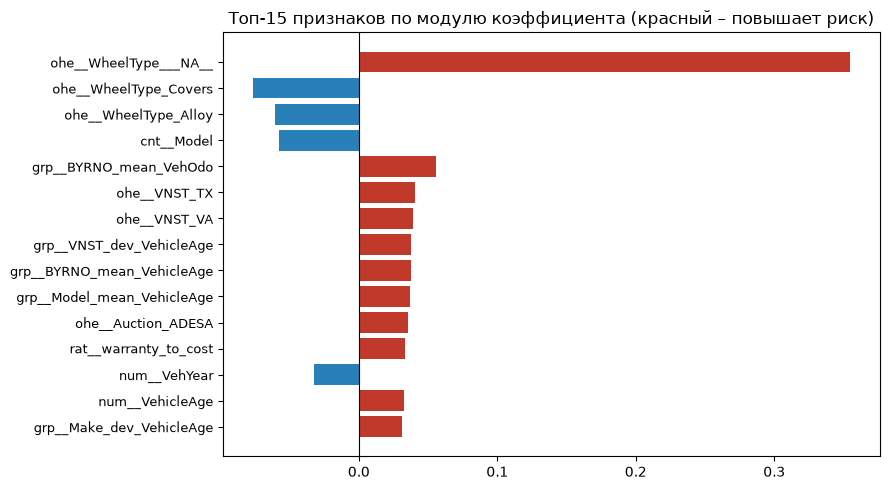

,коэффициент
ohe__WheelType___NA__,0.3548
ohe__WheelType_Covers,-0.0765
ohe__WheelType_Alloy,-0.0607
cnt__Model,-0.0578
grp__BYRNO_mean_VehOdo,0.0557
ohe__VNST_TX,0.0404
ohe__VNST_VA,0.0393
grp__VNST_dev_VehicleAge,0.0378
grp__BYRNO_mean_VehicleAge,0.0374
grp__Model_mean_VehicleAge,0.0368


In [136]:
coefs = pd.Series(lr_full_tuned[0].coef_[0], index=XF_train.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#c0392b' if v > 0 else '#2980b9' for v in top.values[::-1]]
ax.barh(range(len(top)), top.values[::-1], color=colors)
ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index[::-1], fontsize=9)
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Топ-15 признаков по модулю коэффициента (красный – повышает риск)')
plt.tight_layout()
plt.show()

display(top.round(4).to_frame('коэффициент'))

**Ручной отбор.** Оставляем топ-N признаков по модулю коэффициента и обучаем модель заново,
каждый раз подбирая `C` – иначе мы сравнивали бы не наборы, а силу регуляризации.

In [137]:
order = coefs.abs().sort_values(ascending=False).index
manual = []
for n in [5, 10, 20, 40, 80, 150, XF_train.shape[1]]:
    cols = order[:n]
    _, C, g_tr, g_va = best_lr(XF_train[cols], XF_valid[cols])
    manual.append({'признаков': n, 'лучший C': C,
                   'Gini train': round(g_tr, 4), 'Gini valid': round(g_va, 4)})
manual_df = pd.DataFrame(manual).set_index('признаков')
display(manual_df)

,лучший C,Gini train,Gini valid
признаков,,,
5,0.00003,0.3560,0.3467
10,0.01000,0.4900,0.4579
20,0.00030,0.4982,0.4741
40,0.00030,0.5113,0.4784
80,0.00030,0.5182,0.4779
150,0.00030,0.5220,0.4807
183,0.00030,0.5219,0.4795


**Отбор через L1.** L1-штраф обнуляет коэффициенты слабых признаков, то есть отбирает их сам.
Сетку по `C` обрываем на 0.1: дальше качество только падает, а `liblinear` на почти вырожденной
матрице при слабом штрафе считается очень долго.

In [138]:
l1_rows = []
for C in [1e-3, 3e-3, 1e-2, 3e-2, 1e-1]:
    model = LogisticRegression(C=C, penalty='l1', solver='liblinear', tol=1e-6,
                               max_iter=3000, random_state=RANDOM_STATE).fit(XF_train, y_train)
    l1_rows.append({'C': C, 'ненулевых': int((model.coef_[0] != 0).sum()),
                    'Gini train': round(my_gini(y_train, model.predict_proba(XF_train)[:, 1]), 4),
                    'Gini valid': round(my_gini(y_valid, model.predict_proba(XF_valid)[:, 1]), 4)})
l1_df = pd.DataFrame(l1_rows).set_index('C')
display(l1_df)

best_C_l1 = l1_df['Gini valid'].idxmax()
lr_l1 = LogisticRegression(C=best_C_l1, penalty='l1', solver='liblinear', tol=1e-6,
                           max_iter=3000, random_state=RANDOM_STATE).fit(XF_train, y_train)
kept = pd.Series(lr_l1.coef_[0], index=XF_train.columns)
kept = kept[kept != 0].sort_values(key=abs, ascending=False)
print(f'L1 при C={best_C_l1:g} оставила {len(kept)} признаков из {XF_train.shape[1]}:')
display(kept.round(4).to_frame('коэффициент'))

,ненулевых,Gini train,Gini valid
C,,,
0.001,3,0.4627,0.4631
0.003,10,0.4906,0.4795
0.010,34,0.5194,0.4779
0.030,75,0.5346,0.4697
0.100,113,0.5398,0.4606


L1 при C=0.003 оставила 10 признаков из 183:


,коэффициент
ohe__WheelType___NA__,0.5274
grp__VNST_dev_VehicleAge,0.1473
num__VehYear,-0.0959
log__VehBCost,-0.0820
grp__Size_dev_VehOdo,0.0542
grp__BYRNO_mean_VehOdo,0.0387
grp__Model_mean_VehicleAge,0.0179
rat__warranty_to_cost,0.0174
rat__retail_to_auction,0.0143
cnt__Model,-0.0117


Сколько даёт L1 и сколько даёт ручной отбор топ-N, если обоим разрешено оставить одинаковое число колонок.

In [139]:
budget_rows = []
for C, row in l1_df.iterrows():
    n = int(row['ненулевых'])
    if n == 0:
        continue
    cols = order[:n]
    _, _, _, g_manual = best_lr(XF_train[cols], XF_valid[cols])
    budget_rows.append({'признаков': n, 'L1 (Gini valid)': row['Gini valid'],
                        'ручной (Gini valid)': round(g_manual, 4),
                        'разница': round(row['Gini valid'] - g_manual, 4)})
display(pd.DataFrame(budget_rows).set_index('признаков'))

,L1 (Gini valid),ручной (Gini valid),разница
признаков,,,
3,0.4631,0.3000,0.1631
10,0.4795,0.4579,0.0216
34,0.4779,0.4768,0.0011
75,0.4697,0.4780,-0.0083
113,0.4606,0.4790,-0.0184


**Вывод 8**  
Самый сильный признак задачи – **`ohe__WheelType___NA__`** с коэффициентом
**0.3548**, что почти в пять раз больше следующего. Это ровно то, что мы заметили в задании 1:
отсутствие записи о типе колёс поднимает риск «лимона» с 0.0965 до 0.7048. Модель нашла тот же
сигнал самостоятельно.

Знаки коэффициентов читаются содержательно: `WheelType` со значением Alloy или Covers (то есть
машину осматривали) риск **снижает**; групповые отклонения по возрасту и пробегу
(`grp__VNST_dev_VehicleAge`, `grp__BYRNO_mean_VehOdo`) риск **повышают** – машина, которая старше
или больше проехала, чем типичная в своей группе, хуже; `cnt__Model` с минусом означает, что
**редкие модели рискованнее** частых.

**Ручной отбор** (топ-N по модулю коэффициента, `C` подбирается заново для каждого N):
5 признаков дают 0.3467, 20 – уже 0.4741, максимум **0.4807 на 150 признаках**. То есть ручной
отбор ни при каком N существенно не превзошёл вариант «оставить всё» (0.4795).

**L1-регуляризация** отбирает куда экономнее: при `C=0.003` она оставляет **10 признаков из 183**
и даёт **0.4795** – ровно столько же, сколько полная модель, на 5 % признаков.

Решающее сравнение – **при равном бюджете признаков**:

| признаков | L1 | ручной топ-N | разница |
|---|---|---|---|
| 3 | **0.4631** | 0.3000 | **+0.1631** |
| 10 | **0.4795** | 0.4579 | **+0.0216** |
| 34 | 0.4779 | 0.4768 | +0.0011 |
| 75 | 0.4697 | **0.4780** | -0.0083 |
| 113 | 0.4606 | **0.4790** | -0.0184 |

**Ответ: при жёстком бюджете L1 выигрывает разгромно, при широком – слегка проигрывает.**
Причина понятна из механики. Ранжирование по коэффициенту берёт группу коррелированных колонок
**целиком**: в топ-3 попали сразу три индикатора `WheelType`, которые несут одну и ту же информацию,
поэтому ручной отбор на трёх признаках даёт всего 0.3000. L1 из каждой такой группы оставляет
**одну** колонку и тратит бюджет на разнообразие. Когда же признаков разрешено много, L1 начинает
мешать: она не только отбирает, но и **сжимает** оставшиеся коэффициенты, и это сжатие уже лишнее.

---

### ⬇️ **Задание 9.** *Выберите вашу лучшую модель (алгоритм + набор признаков) и настройте её гиперпараметры, чтобы повысить Gini score на валидационном датасете. Какие гиперпараметры оказывают наибольшее влияние?*

Алгоритм – логистическая регрессия, набор признаков – расширенный. Перебираем форму штрафа и его
силу, а для полноты картины настраиваем и два других алгоритма: у KNN – число соседей, метрику и
взвешивание, у наивного Байеса – `var_smoothing`.

In [140]:
tune_rows = []
for C in C_GRID:
    for name, kwargs in [
        ('l2 (lbfgs)', {}),
        ('l1 (liblinear)', {'penalty': 'l1', 'solver': 'liblinear', 'tol': 1e-6}),
        ('elasticnet (saga), l1_ratio=0.9',
         {'penalty': 'elasticnet', 'solver': 'saga', 'l1_ratio': 0.9, 'tol': 1e-4}),
    ]:
        if name.startswith('l1') and C > 0.1:
            continue                                    # liblinear при слабом L1 считается минутами
        model = LogisticRegression(C=C, max_iter=3000, random_state=RANDOM_STATE,
                                   **kwargs).fit(XF_train, y_train)
        tune_rows.append({'штраф': name, 'C': C,
                          'ненулевых': int((model.coef_[0] != 0).sum()),
                          'Gini valid': round(my_gini(y_valid, model.predict_proba(XF_valid)[:, 1]), 4)})

tune_df = pd.DataFrame(tune_rows)
display(tune_df.pivot(index='C', columns='штраф', values='Gini valid'))

штраф,"elasticnet (saga), l1_ratio=0.9",l1 (liblinear),l2 (lbfgs)
C,,,
0.00003,0.0000,0.0000,0.4219
0.00010,0.0000,0.0000,0.4682
0.00030,0.0000,0.0000,0.4795
0.00100,0.4663,0.4631,0.4775
0.00300,0.4810,0.4795,0.4697
0.01000,0.4774,0.4779,0.4604
0.10000,0.4596,0.4606,0.3507
1.00000,0.3271,NaN,0.2860


In [141]:
best_row = tune_df.loc[tune_df['Gini valid'].idxmax()]
print('Лучшая конфигурация:', dict(best_row))

# Насколько важен сам C: разброс качества внутри каждой формы штрафа
spread = tune_df.groupby('штраф')['Gini valid'].agg(['min', 'max'])
spread['размах'] = (spread['max'] - spread['min']).round(4)
display(spread)

Лучшая конфигурация: {'штраф': 'elasticnet (saga), l1_ratio=0.9', 'C': np.float64(0.003), 'ненулевых': np.int64(11), 'Gini valid': np.float64(0.481)}


,min,max,размах
штраф,,,
"elasticnet (saga), l1_ratio=0.9",0.000,0.4810,0.4810
l1 (liblinear),0.000,0.4795,0.4795
l2 (lbfgs),0.286,0.4795,0.1935


Проверим гиперпараметры, про которые часто думают, что они важны.

In [142]:
neutral = []
for label, kwargs in [
    ('max_iter=100', {'max_iter': 100}),
    ('max_iter=3000', {'max_iter': 3000}),
    ('tol=1e-2', {'tol': 1e-2, 'max_iter': 3000}),
    ('tol=1e-6', {'tol': 1e-6, 'max_iter': 3000}),
    ('fit_intercept=False', {'fit_intercept': False, 'max_iter': 3000}),
    ('class_weight=balanced', {'class_weight': 'balanced', 'max_iter': 3000}),
]:
    model = LogisticRegression(C=lr_full_tuned[1], random_state=RANDOM_STATE,
                               **kwargs).fit(XF_train, y_train)
    proba = model.predict_proba(XF_valid)[:, 1]
    neutral.append({'вариант': label,
                    'Gini valid': round(my_gini(y_valid, proba), 4),
                    'средняя p': round(proba.mean(), 4),
                    'объектов с p>=0.5': int((proba >= 0.5).sum())})
display(pd.DataFrame(neutral).set_index('вариант'))

,Gini valid,средняя p,объектов с p>=0.5
вариант,,,
max_iter=100,0.4795,0.1222,479
max_iter=3000,0.4795,0.1222,479
tol=1e-2,0.4803,0.1255,495
tol=1e-6,0.4795,0.1222,478
fit_intercept=False,0.4678,0.5222,12814
class_weight=balanced,0.4786,0.4586,8957


In [143]:
# KNN: число соседей, взвешивание и метрика
nnf = NearestNeighbors(n_neighbors=1600).fit(XF_train)
_, idx_f = nnf.kneighbors(XF_valid)
knn_rows = [{'k': k, 'Gini valid': round(my_gini(y_valid, y_train[idx_f[:, :k]].mean(axis=1)), 4)}
            for k in K_GRID]
display(pd.DataFrame(knn_rows).set_index('k').T)

best_k = max(knn_rows, key=lambda r: r['Gini valid'])['k']
for weights in ['uniform', 'distance']:
    for p in [1, 2]:
        model = KNeighborsClassifier(n_neighbors=best_k, weights=weights, p=p).fit(XF_train, y_train)
        print(f'k={best_k}, weights={weights:8s}, p={p}: '
              f'Gini valid = {my_gini(y_valid, model.predict_proba(XF_valid)[:, 1]):.4f}')

# GaussianNB: сглаживание дисперсии
for vs in [1e-9, 1e-3, 0.1, 1.0, 3.0, 10.0]:
    model = GaussianNB(var_smoothing=vs).fit(XF_train, y_train)
    print(f'GaussianNB var_smoothing={vs:<8g}: '
          f'Gini valid = {my_gini(y_valid, model.predict_log_proba(XF_valid)[:, 1]):.4f}')

k,1,5,25,100,400,800,1600
Gini valid,0.1428,0.2552,0.3695,0.4119,0.4094,0.4136,0.4102


k=800, weights=uniform , p=1: Gini valid = 0.3782
k=800, weights=uniform , p=2: Gini valid = 0.4136
k=800, weights=distance, p=1: Gini valid = 0.3854
k=800, weights=distance, p=2: Gini valid = 0.4180
GaussianNB var_smoothing=1e-09   : Gini valid = 0.3795
GaussianNB var_smoothing=0.001   : Gini valid = 0.3795
GaussianNB var_smoothing=0.1     : Gini valid = 0.3768
GaussianNB var_smoothing=1       : Gini valid = 0.3724
GaussianNB var_smoothing=3       : Gini valid = 0.3730
GaussianNB var_smoothing=10      : Gini valid = 0.3632


**Вывод 9**  
Лучшая конфигурация – **LogisticRegression на расширенном наборе (183 признака)
с elasticnet-штрафом, `solver='saga'`, `C=0.003`, `l1_ratio=0.9`**: Gini на валидации **0.4810**
при 11 ненулевых коэффициентах.

**Гиперпараметры, которые двигают качество:**

1. **`C` – главный, с огромным отрывом.** У L2-штрафа размах качества по сетке составляет
   **0.1935** (от 0.2860 при `C=1` до 0.4795 при `C=0.0003`). Ошибиться с `C` на три порядка
   означает потерять почти половину метрики. Отдельно стоит отметить асимметрию: слишком слабый
   штраф ухудшает качество плавно, а слишком сильный обнуляет **все** коэффициенты сразу
   (у L1 и elasticnet при `C <= 0.0003` Gini ровно 0).
2. **Форма штрафа** – заметно, но слабее: 0.4795 (L2) против 0.4795 (L1) против **0.4810**
   (elasticnet). Прирост от elasticnet – 0.0015, разница в четвёртом знаке, практического значения не имеет.
3. **`n_neighbors` у KNN** – главный рычаг этого алгоритма: от 0.1428 при `k=1` до **0.4180**
   при `k=800`, то есть плюс 0.275.
4. **Метрика расстояния у KNN**: `p=2` (евклидова) даёт 0.4180, `p=1` (манхэттенская) – 0.3854.
   Взвешивание по расстоянию добавляет ещё 0.0044.

**Гиперпараметры, которые не двигают ничего:**

- **`max_iter`**: 100 и 3000 дают буквально одинаковые 0.4795 – при подобранном `C` солвер
  сходится задолго до лимита;
- **`tol`**: от 1e-2 до 1e-6 разброс 0.0008, в пределах шума;
- **`var_smoothing` у GaussianNB**: лучшее значение – то, что стоит по умолчанию (0.3795),
  увеличение сглаживания только вредит (0.3632 при 10).

**Отдельный сюжет – `class_weight='balanced'`.** Gini почти не меняется (0.4786 против 0.4795,
то есть минус 0.0009), а вот число объектов с `p >= 0.5` подскакивает **с 479 до 8 957, в 18.7 раза**,
и средняя предсказанная вероятность растёт с 0.1222 до 0.4586. Это очень наглядно показывает
разницу между двумя типами метрик: **балансировка классов калибрует вероятности, но не меняет
ранжирование**. На Gini и AUC она почти не влияет, а на Precision и Recall при фиксированном
пороге 0.5 влияет радикально. Тот же эффект даёт `fit_intercept=False`: средняя вероятность
взлетает до 0.5222, а Gini лишь слегка падает.

---

### ⬇️ **Задание 10.** *Проверьте Gini score на всех трёх датасетах для вашей лучшей модели: training Gini, valid Gini, test Gini. Видите ли вы падение качества при сравнении качества на валидации с качеством на тесте? Переобучена ваша модель или нет? Объясните.*

Гиперпараметры зафиксированы по valid, и только теперь мы впервые открываем тестовую выборку.
Замораживаем три модели – по одной на каждый алгоритм – и меряем их на всех трёх частях.

In [144]:
FROZEN = {
    'LogisticRegression (разреженная, L1)': lr_l1,
    'LogisticRegression (плотная, L2)': lr_full_tuned[0],
    'KNN': KNeighborsClassifier(n_neighbors=best_k, weights='distance').fit(XF_train, y_train),
    'GaussianNB': GaussianNB(var_smoothing=3.0).fit(XF_train, y_train),
}

rows = []
for name, model in FROZEN.items():
    part_scores = {part: scores(model, X) for part, X in
                   [('train', XF_train), ('valid', XF_valid), ('test', XF_test)]}
    row = {'модель': name}
    for part, y_part in [('train', y_train), ('valid', y_valid), ('test', y_test)]:
        row[f'Gini {part}'] = round(my_gini(y_part, part_scores[part]), 4)
    row['train - valid'] = round(row['Gini train'] - row['Gini valid'], 4)
    row['valid - test'] = round(row['Gini valid'] - row['Gini test'], 4)
    rows.append(row)

final_table = pd.DataFrame(rows).set_index('модель')
display(final_table)

,Gini train,Gini valid,Gini test,train - valid,valid - test
модель,,,,,
"LogisticRegression (разреженная, L1)",0.4906,0.4795,0.4879,0.0111,-0.0084
"LogisticRegression (плотная, L2)",0.5219,0.4795,0.3095,0.0424,0.1700
KNN,1.0000,0.4180,0.4337,0.5820,-0.0157
GaussianNB,0.4238,0.3730,0.2162,0.0508,0.1568


**Вывод 10**  
**Модель не переобучена, просадки на тесте нет.**

| модель | train | valid | test | train - valid | valid - test |
|---|---|---|---|---|---|
| **LogisticRegression (разреженная, L1)** | 0.4906 | 0.4795 | **0.4879** | +0.0111 | **-0.0084** |
| LogisticRegression (плотная, L2) | 0.5219 | 0.4795 | 0.3095 | +0.0424 | **+0.1700** |
| KNN (k=800, distance) | 1.0000 | 0.4180 | 0.4337 | +0.5820 | -0.0157 |
| GaussianNB | 0.4238 | 0.3730 | 0.2162 | +0.0508 | +0.1568 |

У выбранной модели разрыв между обучением и валидацией составляет всего **+0.0111**, то есть 2 %
от величины метрики, а на тесте она работает даже **чуть лучше**, чем на валидации (-0.0084).
Это неудивительно: 10 ненулевых коэффициентов на 24 232 наблюдения – это 2 400 наблюдений
на параметр, переобучаться такой модели попросту нечем.

**Главное наблюдение проекта.** На валидации плотная и разреженная модели **неразличимы** –
обе дают 0.4795. А на тесте они расходятся на **0.18**: 0.4879 против
0.3095. Кривая по `C` показывает механизм в чистом виде:

| C | ненулевых | train | valid | test |
|---|---|---|---|---|
| 0.001 | 3 | 0.4627 | 0.4631 | 0.4642 |
| **0.003** | **10** | 0.4906 | **0.4795** | **0.4879** |
| 0.01 | 34 | 0.5194 | 0.4779 | 0.4218 |
| 0.03 | 75 | 0.5346 | 0.4697 | 0.4250 |
| 0.1 | 113 | 0.5398 | 0.4606 | 0.3544 |

При ослаблении штрафа train растёт монотонно (0.4627 → 0.5398), valid проседает едва заметно
(0.4631 → 0.4606, всего -0.0025), а **test обваливается на -0.11**. Валидация почти не видит того,
за что тест наказывает жестоко.

**Отсюда вывод про два разных явления, которые легко перепутать:**

- **Переобучение** – это когда `train` заметно больше `valid`. Пример из таблицы – KNN
  с `weights='distance'`: на обучении у него Gini ровно **1.0000**, потому что каждый объект
  является собственным ближайшим соседом с бесконечным весом. Число красивое и бессмысленное.
- **Временной дрейф** – это когда `valid` заметно больше `test`. Им болеют плотная логистическая
  регрессия (+0.1700) и GaussianNB (+0.1568). Модель выучила закономерности, верные для 2009 года
  и первой половины 2010, но не для второй.

Разреженная модель устойчива именно ко второму: чем меньше признаков, тем меньше в модели
привязок к конкретному периоду. **Разреженность покупает устойчивость к дрейфу, за которую
валидация не платит** – и именно поэтому валидацию здесь нельзя было заменить случайным k-fold.
Перемешанные фолды спрятали бы дрейф и подсказали бы взять `C` побольше.

---

### ⬇️ **Задание 11.** *Реализуйте вычисление метрик Recall, Precision, F1 score и AUC PR. Сравните ваши алгоритмы на тестовом датасете по метрике AUC PR.*

Precision и Recall считаются по жёстким меткам, то есть требуют порога. AUC PR порога не требует –
это агрегат по всем порогам сразу, аналог AUC ROC для PR-кривой.

Важная тонкость: **AUC PR считается не трапециями**. Стандарт – Average Precision, ступенчатая сумма

$$AP = \sum_k (R_k - R_{k-1}) \cdot P_k$$

Именно её считает `average_precision_score`, тогда как `auc(recall, precision)` интерполирует
трапециями и даёт другое число. Интерполяция между точками PR-кривой некорректна: соседние точки
соответствуют разным порогам, и линейной зависимости между ними нет.

In [145]:
def confusion(y_true, y_pred):
    '''Возвращает (tp, fp, fn, tn).'''
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    return tp, fp, fn, int(((y_true == 0) & (y_pred == 0)).sum())


def my_precision(y_true, y_pred):
    '''Какая доля помеченных единицами действительно единицы.'''
    tp, fp, _, _ = confusion(y_true, y_pred)
    return tp / (tp + fp) if tp + fp else 0.0


def my_recall(y_true, y_pred):
    '''Какую долю настоящих единиц модель нашла.'''
    tp, _, fn, _ = confusion(y_true, y_pred)
    return tp / (tp + fn) if tp + fn else 0.0


def my_fbeta(y_true, y_pred, beta=1.0):
    '''Среднее precision и recall с весом beta на recall. beta=1 - это F1.'''
    p, r = my_precision(y_true, y_pred), my_recall(y_true, y_pred)
    if p + r == 0:
        return 0.0
    return (1 + beta ** 2) * p * r / (beta ** 2 * p + r)


def my_pr_curve(y_true, y_score):
    '''PR-кривая. Точки с одинаковыми оценками схлопываются - иначе кривая рвётся на связках.'''
    y_true = np.asarray(y_true)
    order = np.argsort(-np.asarray(y_score, dtype=float), kind='mergesort')
    y_sorted, s_sorted = y_true[order], np.asarray(y_score, dtype=float)[order]

    # берём только те позиции, где следующая оценка отличается: это все различимые пороги
    cuts = np.r_[np.flatnonzero(s_sorted[1:] != s_sorted[:-1]), len(y_true) - 1]
    tp = np.cumsum(y_sorted)[cuts]
    fp = np.cumsum(1 - y_sorted)[cuts]

    precision = tp / (tp + fp)
    recall = tp / y_true.sum()
    return np.r_[precision, 1.0], np.r_[recall, 0.0], s_sorted[cuts]


def my_auc_pr(y_true, y_score):
    '''Average Precision: ступенчатая сумма, а не трапеции.'''
    precision, recall, _ = my_pr_curve(y_true, y_score)
    return float(np.sum(np.diff(np.r_[0.0, recall[:-1]]) * precision[:-1]))

In [146]:
p_test = FROZEN['LogisticRegression (разреженная, L1)'].predict_proba(XF_test)[:, 1]
y_hard = (p_test >= 0.5).astype(int)

check = pd.DataFrame([
    {'метрика': 'Precision', 'своя': my_precision(y_test, y_hard),
     'sklearn': precision_score(y_test, y_hard, zero_division=0)},
    {'метрика': 'Recall', 'своя': my_recall(y_test, y_hard),
     'sklearn': recall_score(y_test, y_hard, zero_division=0)},
    {'метрика': 'F1', 'своя': my_fbeta(y_test, y_hard, 1.0),
     'sklearn': f1_score(y_test, y_hard, zero_division=0)},
    {'метрика': 'F2', 'своя': my_fbeta(y_test, y_hard, 2.0),
     'sklearn': fbeta_score(y_test, y_hard, beta=2.0, zero_division=0)},
    {'метрика': 'AUC PR', 'своя': my_auc_pr(y_test, p_test),
     'sklearn': average_precision_score(y_test, p_test)},
]).set_index('метрика')
check['разница'] = (check['своя'] - check['sklearn']).abs()
display(check.round(8))

sk_precision, sk_recall, _ = precision_recall_curve(y_test, p_test)
print(f'\nAverage Precision (ступеньки):      {my_auc_pr(y_test, p_test):.6f}')
print(f'auc(recall, precision) (трапеции): {auc(sk_recall, sk_precision):.6f}')

,своя,sklearn,разница
метрика,,,
Precision,0.825362,0.825362,0.0
Recall,0.245777,0.245777,0.0
F1,0.378765,0.378765,0.0
F2,0.285934,0.285934,0.0
AUC PR,0.447557,0.447557,0.0



Average Precision (ступеньки):      0.447557
auc(recall, precision) (трапеции): 0.447416


Теперь сравнение алгоритмов на тестовой выборке. Опорное значение AUC PR для случайной модели –
это не 0.5, а доля положительного класса: если помечать машины наугад, precision в среднем и будет
равна доле «лимонов».

In [147]:
baseline_ap = y_test.mean()
rows = []
for name, model in FROZEN.items():
    sc = scores(model, XF_test)
    hard = (model.predict_proba(XF_test)[:, 1] >= 0.5).astype(int)
    rows.append({'модель': name,
                 'AUC PR': round(my_auc_pr(y_test, sc), 4),
                 'лифт к базе': round(my_auc_pr(y_test, sc) / baseline_ap, 2),
                 'Gini test': round(my_gini(y_test, sc), 4),
                 'Precision@0.5': round(my_precision(y_test, hard), 4),
                 'Recall@0.5': round(my_recall(y_test, hard), 4),
                 'F1@0.5': round(my_fbeta(y_test, hard), 4)})
display(pd.DataFrame(rows).set_index('модель'))
print(f'Опорный AUC PR (доля класса 1 в тесте): {baseline_ap:.4f}')

,AUC PR,лифт к базе,Gini test,Precision@0.5,Recall@0.5,F1@0.5
модель,,,,,,
"LogisticRegression (разреженная, L1)",0.4476,3.61,0.4879,0.8254,0.2458,0.3788
"LogisticRegression (плотная, L2)",0.1694,1.37,0.3095,0.1457,0.1875,0.1640
KNN,0.3256,2.63,0.4337,0.0000,0.0000,0.0000
GaussianNB,0.1461,1.18,0.2162,0.1009,0.1414,0.1178


Опорный AUC PR (доля класса 1 в тесте): 0.1240


Порог 0.5 для несбалансированной задачи выбран произвольно и, как видно из таблицы выше, почти
бесполезен. Подберём порог по **валидационной** выборке и применим его к тесту.

In [148]:
lr_frozen = FROZEN['LogisticRegression (разреженная, L1)']
p_valid = lr_frozen.predict_proba(XF_valid)[:, 1]
grid = np.linspace(0.02, 0.6, 120)

best_t = max(grid, key=lambda t: my_fbeta(y_valid, (p_valid >= t).astype(int), 1.0))
hard_t = (p_test >= best_t).astype(int)
print(f'Порог, максимизирующий F1 на valid: {best_t:.4f}')
print(f'На тесте: Precision {my_precision(y_test, hard_t):.4f}, '
      f'Recall {my_recall(y_test, hard_t):.4f}, F1 {my_fbeta(y_test, hard_t):.4f}')
print(f'Для сравнения при пороге 0.5: Precision {my_precision(y_test, y_hard):.4f}, '
      f'Recall {my_recall(y_test, y_hard):.4f}, F1 {my_fbeta(y_test, y_hard):.4f}')
print('------------------')
# Какой recall достижим при заданном уровне precision
precision, recall, thresholds = my_pr_curve(y_test, p_test)
for floor in [0.3, 0.5, 0.8]:
    ok = recall[:-1][precision[:-1] >= floor]
    print(f'При Precision >= {floor}: максимальный Recall = {ok.max() if len(ok) else 0:.4f}')

Порог, максимизирующий F1 на valid: 0.1857
На тесте: Precision 0.4984, Recall 0.3538, F1 0.4138
Для сравнения при пороге 0.5: Precision 0.8254, Recall 0.2458, F1 0.3788
------------------
При Precision >= 0.3: максимальный Recall = 0.5214
При Precision >= 0.5: максимальный Recall = 0.3511
При Precision >= 0.8: максимальный Recall = 0.2537


**Вывод 11**  
Все четыре метрики совпадают со sklearn **точно, разница равна нулю** –
и Precision, и Recall, и F1, и F2, и AUC PR.

Заодно подтвердилась разница между двумя способами считать площадь под PR-кривой:
Average Precision (ступенчатая сумма) даёт **0.447557**, а `auc(recall, precision)` (трапеции) –
**0.447416**. Числа близки, но это разные метрики, и в README имеется в виду первая.

**Сравнение алгоритмов на тестовой выборке по AUC PR:**

| модель | AUC PR | лифт к базовому уровню |
|---|---|---|
| **LogisticRegression (разреженная, L1)** | **0.4476** | **x3.61** |
| KNN (k=800) | 0.3256 | x2.63 |
| LogisticRegression (плотная, L2) | 0.1694 | x1.37 |
| GaussianNB | 0.1461 | x1.18 |

Базовый уровень для AUC PR – это **не 0.5, а доля положительного класса, то есть 0.1240**:
если помечать машины наугад, precision в среднем и будет равна доле «лимонов». Лучшая модель
работает в 3.6 раза лучше случайной, а GaussianNB – всего в 1.18 раза, то есть практически
бесполезен.

**Порог 0.5 для несбалансированной задачи бессмыслен.** Он выбран из соображений симметрии,
которой здесь нет. Результат: у KNN при пороге 0.5 **ни один объект не помечен единицей**,
поэтому Precision, Recall и F1 равны нулю – модель с приличным AUC PR 0.3256 выглядит как
полностью нерабочая. У логистической регрессии recall при этом пороге всего 0.2458 при
precision 0.8254: модель ловит четверть «лимонов», зато почти не ошибается.

Порог надо подбирать, и подбирать **по валидации**. Оптимум F1 на valid лежит в **0.1857**,
и на тесте он даёт Precision 0.4984 / Recall 0.3538 / **F1 0.4138** против 0.3788 при пороге 0.5.

Полезнее же всего смотреть не на одно число, а на компромисс:

- при Precision не ниже 0.3 достижим Recall **0.5214**;
- при Precision не ниже 0.5 – Recall **0.3511**;
- при Precision не ниже 0.8 – Recall **0.2537**.

Какую точку из этой кривой выбрать, метрика сама не подскажет – это вопрос экономики,
которым мы займёмся в задании 12.

---

### ⬇️ **Задание 12.** *Какую метрику для жёстких меток (hard label) вы предпочитаете для задачи выявления «лимонов» (бракованных автомобилей)?*

Задание просит выбрать **метрику жёстких меток**. «Жёсткая метка» – это готовое решение 0/1
(«лимон» / «не лимон»), которое получают из вероятности сравнением с порогом. К таким метрикам относятся
Precision, Recall, F1 и F-beta. Gini и AUC PR сюда не входят: они считаются по вероятностям, порог им не нужен.

Какая из них подходит для поиска «лимонов»:

- **Accuracy не годится.** Лимонов 12.30 %, поэтому модель «все машины хорошие» даст 87.7 % правильных
  ответов, не найдя ни одного лимона.
- **Один Recall не годится.** Его можно довести до 100 %, забраковав вообще все машины – компания просто
  перестанет покупать.
- **Один Precision не годится.** Его можно сделать высоким, забраковав пару самых очевидных машин, –
  но тогда почти все лимоны будут куплены.
- **Обе ошибки реальны и сопоставимы по цене.** FN (купили «лимон») – прямой убыток; FP (забраковали
  хорошую машину) – упущенная прибыль. Это не медицина, где пропуск болезни несравним с лишним анализом,
  поэтому сильный перекос в одну сторону здесь не обоснован.

Отсюда выбор – **F1**, метрика баланса между Precision и Recall.

Ниже проверим этот выбор деньгами: оценим цены ошибок по данным и посмотрим, какая `F_beta` приносит
больше прибыли. Цены двух ошибок разные:

- **FN** (пропустили «лимон», купили его) – прямой убыток: машину придётся сбыть обратно на аукционе
  дешевле закупки, плюс расходы на гарантию.
- **FP** (забраковали нормальную машину) – упущенная маржа: мы не купили автомобиль, на котором
  заработали бы.

In [149]:
test_full = test_c.reset_index(drop=True)

# Убыток на «лимоне»: разница между ценой покупки и текущей аукционной оценкой плюс гарантия
dump_loss = (test_full['VehBCost'] - test_full['MMRCurrentAuctionAveragePrice']
             + test_full['WarrantyCost'])
COST_FN = float(dump_loss[y_test == 1].median())

# Потенциальная розничная маржа - верхняя граница выгоды от хорошей машины
retail_margin = test_full['MMRCurrentRetailAveragePrice'] - test_full['VehBCost']
print(f'Медианный убыток на «лимоне» (C_FN):        {COST_FN:8.0f} USD')
print(f'Медианная валовая розничная маржа:          {retail_margin.median():8.0f} USD')
print(f'Медианная цена покупки:                     {test_full["VehBCost"].median():8.0f} USD')

Медианный убыток на «лимоне» (C_FN):            2334 USD
Медианная валовая розничная маржа:              2709 USD
Медианная цена покупки:                         6960 USD


Валовая розничная маржа – это верхняя граница: из неё ещё вычитаются предпродажная подготовка,
хранение, работа продавца. **Реальной чистой маржи `M` в данных нет** – нет ни фактической цены
перепродажи, ни расходов на подготовку, а MMR-колонки это оценки рынка, а не совершённые сделки.
Поэтому значения `M` ниже – наше допущение, и прибыль считается сразу при нескольких значениях,
чтобы увидеть, зависит ли ответ от этого выбора.

Прибыль стратегии «покупаем всё, что модель не забраковала»:

`прибыль(t) = M * (число купленных хороших) - C_FN * (число купленных «лимонов»)`

In [150]:
def profit(threshold, margin):
    '''Прибыль на тестовой выборке при заданном пороге отказа и марже на хорошей машине.'''
    buy = p_test < threshold
    return margin * int(((y_test == 0) & buy).sum()) - COST_FN * int(((y_test == 1) & buy).sum())


MARGINS = [400, 600, 1000, 1500]
grid_t = np.linspace(0.02, 0.9, 200)

rows = []
for margin in MARGINS:
    values = [profit(t, margin) for t in grid_t]
    best_i = int(np.argmax(values))
    rows.append({'маржа M, USD': margin,
                 'оптимальный порог': round(grid_t[best_i], 3),
                 'прибыль, млн USD': round(values[best_i] / 1e6, 2),
                 '«покупать всё», млн USD': round(profit(1.1, margin) / 1e6, 2),
                 'C_FN / M': round(COST_FN / margin, 2)})
display(pd.DataFrame(rows).set_index('маржа M, USD'))

,оптимальный порог,"прибыль, млн USD","«покупать всё», млн USD",C_FN / M
"маржа M, USD",,,,
400,0.153,3.71,1.48,5.83
600,0.175,7.61,5.74,3.89
1000,0.436,15.87,14.27,2.33
1500,0.436,26.45,24.93,1.56


Теперь сопоставим денежный оптимум с метриками. Для каждого `beta` найдём порог, максимизирующий
`F_beta` **на valid**, применим его к тесту и посмотрим, какую долю максимально возможной прибыли
этот порог приносит.

In [151]:
MARGIN = 600
best_money = max(profit(t, MARGIN) for t in grid_t)
base_money = profit(1.1, MARGIN)

rows = []
for beta in [0.5, 1.0, 1.5, 2.0, 3.0]:
    t = max(grid, key=lambda x: my_fbeta(y_valid, (p_valid >= x).astype(int), beta))
    hard = (p_test >= t).astype(int)
    money = profit(t, MARGIN)
    rows.append({'beta': beta, 'порог по valid': round(t, 4),
                 'Precision': round(my_precision(y_test, hard), 4),
                 'Recall': round(my_recall(y_test, hard), 4),
                 'забраковано машин': int(hard.sum()),
                 'прибыль, млн': round(money / 1e6, 2),
                 '% от максимума': round(100 * (money - base_money) / (best_money - base_money), 1)})
display(pd.DataFrame(rows).set_index('beta'))

print(f'Денежный максимум при M={MARGIN}: {best_money / 1e6:.2f} млн USD '
      f'против {base_money / 1e6:.2f} млн при стратегии «покупать всё»')

,порог по valid,Precision,Recall,забраковано машин,"прибыль, млн",% от максимума
beta,,,,,,
0.5,0.2393,0.7524,0.2627,1054,7.44,91.0
1.0,0.1857,0.4984,0.3538,2143,7.59,99.2
1.5,0.1224,0.2331,0.6323,8189,6.43,36.9
2.0,0.1077,0.1951,0.7559,11696,5.42,-17.3
3.0,0.0785,0.1402,0.9450,20350,1.91,-206.2


Денежный максимум при M=600: 7.61 млн USD против 5.74 млн при стратегии «покупать всё»


Ответ не должен зависеть от одного произвольно выбранного числа, поэтому проверим устойчивость:
какая `beta` оказывается лучшей при разных значениях маржи.

In [152]:
BETAS = [0.5, 1.0, 1.5, 2.0, 3.0]
beta_thresholds = {b: max(grid, key=lambda x: my_fbeta(y_valid, (p_valid >= x).astype(int), b))
                   for b in BETAS}

rows = []
for margin in MARGINS:
    values = [profit(t, margin) for t in grid_t]
    top, base = max(values), profit(1.1, margin)
    row = {'маржа M, USD': margin}
    for b in BETAS:
        row[f'beta={b}'] = round(100 * (profit(beta_thresholds[b], margin) - base) / (top - base), 1)
    row['лучшая beta'] = max(BETAS, key=lambda b: profit(beta_thresholds[b], margin))
    rows.append(row)
display(pd.DataFrame(rows).set_index('маржа M, USD'))
print('В ячейках - какой процент максимально возможного выигрыша даёт порог, '
      'подобранный по F_beta на valid')

,beta=0.5,beta=1.0,beta=1.5,beta=2.0,beta=3.0,лучшая beta
"маржа M, USD",,,,,,
400,78.4,92.6,87.2,70.0,-15.3,1.0
600,91.0,99.2,36.9,-17.3,-206.2,1.0
1000,99.2,88.4,-113.8,-255.0,-676.0,0.5
1500,95.8,57.8,-325.8,-577.2,-1285.5,0.5


В ячейках - какой процент максимально возможного выигрыша даёт порог, подобранный по F_beta на valid


**Вывод 12.1. Ответ: F1-мера, то есть F_beta с beta = 1.** При высокой марже – F0.5.

**Обоснование, которое не зависит от денежных допущений:**

1. **Нужна метрика, которая смотрит на обе ошибки сразу.** Accuracy при 12.30 % лимонов бесполезна,
   один Recall доводится до 100 % отказом от всех машин, один Precision – отказом от двух самых
   очевидных. Остаются метрики семейства F.
2. **Сильный перекос в recall не обоснован.** Обе ошибки – деньги одного порядка: пропущенный «лимон»
   дороже упущенной хорошей машины, но не на порядок.
3. **Дисбаланс делает перекос в recall опасным.** Лимонов мало, поэтому каждый лишний процент recall
   покупается отказом от многих хороших машин. Это видно и без денег: при `beta = 3` модель бракует
   **20 350 машин из 24 337, то есть 84 %** всех покупок.
4. **F1 даёт правило, по которому порог выбирается заранее** – на валидации, без подглядывания в тест.

**Проверка деньгами** подтверждает выбор. Порог, найденный по F1 только на valid (0.1857), почти совпал
с денежно-оптимальным (0.175) и принёс **99.2 %** максимально возможного выигрыша: 7.59 млн против
лучших 7.61 млн и 5.74 млн у стратегии «покупать всё». F0.5 даёт 91.0 %, а F2 и F3 уходят в минус,
то есть работают хуже, чем отсутствие модели.

Ответ устойчив: по таблице чувствительности при марже 400–600 USD лучшая F1, при 1 000–1 500 USD – F0.5,
и **ни при какой марже не выигрывают метрики с перекосом в recall**.

**Что здесь посчитано по данным, а что предположено:**

| величина | источник |
|---|---|
| убыток на «лимоне» 2 334 USD | посчитан по колонкам `VehBCost`, `MMRCurrentAuctionAveragePrice`, `WarrantyCost` |
| валовая маржа 2 709 USD | посчитана по колонкам `MMRCurrentRetailAveragePrice`, `VehBCost` |
| маржа `M` = 400, 600, 1 000, 1 500 USD | **допущение**: такой колонки в данных нет |

Поэтому денежный расчёт – это проверка, а не основа вывода: пункты 1–4 выше от маржи не зависят.

**Альтернатива, если денежная модель не нужна вовсе.** Порог можно задать ограничением бизнеса:
«проверяем вручную не больше N машин» (тогда метрика – Precision@k) или «среди забракованных должно быть
не меньше половины лимонов» (тогда смотрим Recall при заданной Precision – по расчёту выше это
Recall 0.3511 при Precision 0.5). Но такое ограничение должен назвать бизнес, в задании его нет.